# Análisis Exploratorio — Infraestructura de Carga para VE

**Proyecto:** Visualización de la accesibilidad territorial de la infraestructura de carga para distintos rangos de autonomía.

**Objetivo del notebook:** Evaluar la factibilidad de cada tarea propuesta:
1. Caracterizar cantidad y capacidad de las instalaciones.
2. Explorar la distribución espacial.
3. Analizar la separación entre puntos de carga.
4. Comparar separaciones con distintos rangos de autonomía.

## 0. Imports y carga de datos

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy.spatial.distance import cdist
from scipy.spatial import cKDTree

# Paleta de colores consistente con el estilo del curso
MAGENTA = "#ecc47e"
AZUL    = "#3222A6"
GRIS    = "#BDBDBD"
NARANJA = "#E68200"

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
})

# ----- Carga -----
priv = pd.read_excel("C:\\Users\\Lenovo\\infovis\\InfoVis\\datasets\\PRIVADAS.xlsx", parse_dates=False)
pub  = pd.read_excel("C:\\Users\\Lenovo\\infovis\\InfoVis\\datasets\\PÚBLICAS.xlsx",  parse_dates=False)

# Parsear fechas manualmente (formato DD-MM-YYYY)
for df in (priv, pub):
    df["FECHA"] = pd.to_datetime(df["FECHA_INSCRIPCIÓN"], dayfirst=True, errors="coerce")
    df["AÑO"]   = df["FECHA"].dt.year

print(f"Instalaciones privadas : {len(priv):>5,}")
print(f"Instalaciones públicas : {len(pub):>5,}")
print(f"Total                  : {len(priv)+len(pub):>5,}")

Instalaciones privadas : 3,032
Instalaciones públicas :   599
Total                  : 3,631


---
## Tarea 1 — Caracterizar cantidad y capacidad de las instalaciones

**Factibilidad:** Variables `CANTIDAD_CARGADORES` y `POTENCIA_ELECTROMOVILIDAD` sin valores faltantes en ambos archivos.

### 1a. Cobertura y valores faltantes

In [2]:
print("=== PRIVADAS — valores faltantes ===")
print(priv.isnull().sum().to_string())
print()
print("=== PÚBLICAS — valores faltantes ===")
print(pub.isnull().sum().to_string())

=== PRIVADAS — valores faltantes ===
ID_INSTALACION               0
FECHA_INSCRIPCIÓN            0
COMUNA_INSTALACION           0
REGION_INSTALACION           0
CANTIDAD_CARGADORES          0
POTENCIA_ELECTROMOVILIDAD    0
FECHA                        0
AÑO                          0

=== PÚBLICAS — valores faltantes ===
ID_INSTALACION               0
IDENTIFICADOR_INSTALACION    0
FECHA_INSCRIPCIÓN            0
COMUNA_INSTALACION           0
REGION_INSTALACION           0
LATITUD                      0
LONGITUD                     0
CANTIDAD_CARGADORES          0
POTENCIA_ELECTROMOVILIDAD    0
FECHA                        0
AÑO                          0


### 1b. Estadísticos descriptivos de cargadores y potencia

In [3]:
vars_cap = ["CANTIDAD_CARGADORES", "POTENCIA_ELECTROMOVILIDAD"]

desc_priv = priv[vars_cap].describe().T
desc_priv.index = ["Cargadores (priv.)", "Potencia kW (priv.)"]

desc_pub = pub[vars_cap].describe().T
desc_pub.index = ["Cargadores (públ.)", "Potencia kW (públ.)"]

resumen = pd.concat([desc_priv, desc_pub]).round(2)
print(resumen[["count", "mean", "std", "min", "50%", "max"]])

                      count   mean     std  min   50%     max
Cargadores (priv.)   3032.0   1.32    2.30  1.0   1.0    64.0
Potencia kW (priv.)  3032.0  13.99   41.16  0.0   7.4   811.3
Cargadores (públ.)    599.0   2.55    9.62  1.0   1.0   106.0
Potencia kW (públ.)   599.0  89.40  131.39  2.8  44.0  1042.8


### 1c. Distribución de potencia por tipo (pública vs. privada)

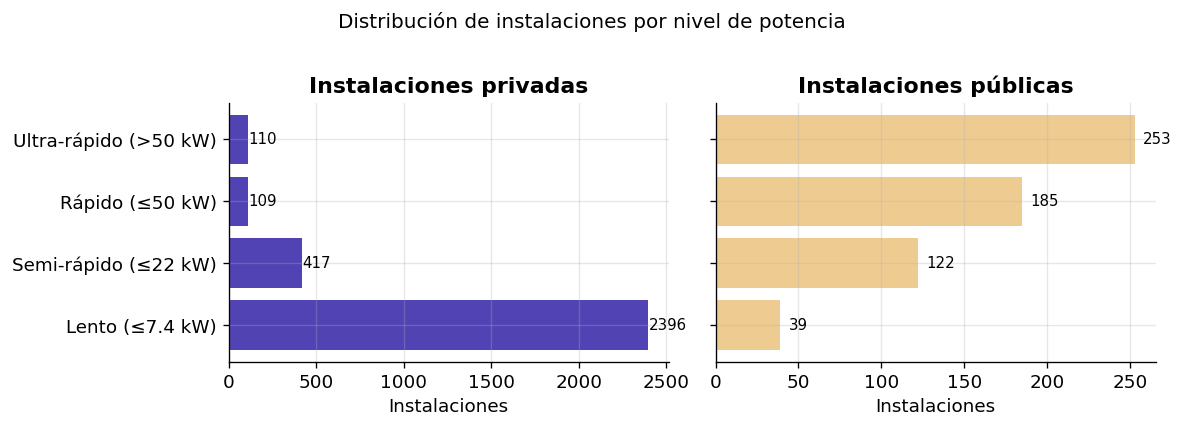


Conclusión: la potencia existe y tiene variabilidad → Tarea 1 FACTIBLE


In [4]:
# Clasificación de nivel de carga según kW
def nivel_carga(kw):
    if kw <= 7.4:
        return "Lento (≤7.4 kW)"
    elif kw <= 22:
        return "Semi-rápido (≤22 kW)"
    elif kw <= 50:
        return "Rápido (≤50 kW)"
    else:
        return "Ultra-rápido (>50 kW)"

orden_nivel = ["Lento (≤7.4 kW)", "Semi-rápido (≤22 kW)", "Rápido (≤50 kW)", "Ultra-rápido (>50 kW)"]

priv["NIVEL"] = priv["POTENCIA_ELECTROMOVILIDAD"].apply(nivel_carga)
pub["NIVEL"]  = pub["POTENCIA_ELECTROMOVILIDAD"].apply(nivel_carga)

# Contar por nivel
cnt_priv = priv["NIVEL"].value_counts().reindex(orden_nivel, fill_value=0)
cnt_pub  = pub["NIVEL"].value_counts().reindex(orden_nivel, fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)

for ax, cnt, titulo, color in zip(
    axes,
    [cnt_priv, cnt_pub],
    ["Instalaciones privadas", "Instalaciones públicas"],
    [AZUL, MAGENTA]
):
    ax.barh(cnt.index, cnt.values, color=color, alpha=0.85)
    ax.set_xlabel("Instalaciones")
    ax.set_title(titulo, fontweight="bold")
    for i, v in enumerate(cnt.values):
        ax.text(v + 5, i, str(v), va="center", fontsize=9)

fig.suptitle("Distribución de instalaciones por nivel de potencia", fontsize=12, y=1.01)
plt.tight_layout()
plt.show()

print("\nConclusión: la potencia existe y tiene variabilidad → Tarea 1 FACTIBLE")

### 1d. Distribución de cargadores por instalación

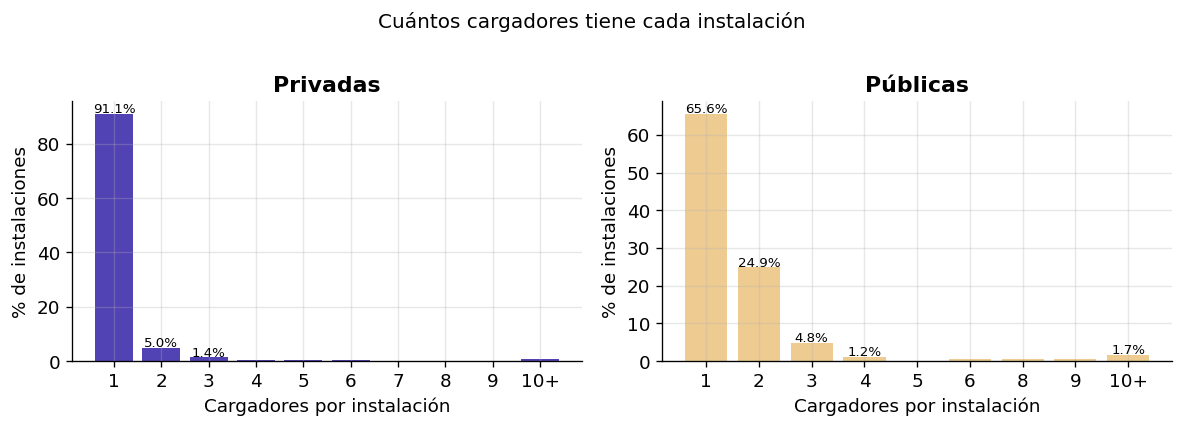

La mayoría de instalaciones privadas tiene 1 cargador; las públicas tienen mayor variabilidad.


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))

for ax, df, titulo, color in zip(
    axes,
    [priv, pub],
    ["Privadas", "Públicas"],
    [AZUL, MAGENTA]
):
    # Agrupar valores grandes en "10+"
    vals = df["CANTIDAD_CARGADORES"].clip(upper=10)
    cnt  = vals.value_counts().sort_index()
    etiq = [str(int(v)) if v < 10 else "10+" for v in cnt.index]
    pct  = 100 * cnt / cnt.sum()
    bars = ax.bar(etiq, pct.values, color=color, alpha=0.85)
    ax.set_xlabel("Cargadores por instalación")
    ax.set_ylabel("% de instalaciones")
    ax.set_title(titulo, fontweight="bold")
    for bar, p in zip(bars, pct.values):
        if p > 1:
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                    f"{p:.1f}%", ha="center", fontsize=8)

fig.suptitle("Cuántos cargadores tiene cada instalación", fontsize=12, y=1.01)
plt.tight_layout()
plt.show()

print("La mayoría de instalaciones privadas tiene 1 cargador; las públicas tienen mayor variabilidad.")

### 1e. Crecimiento temporal de la red

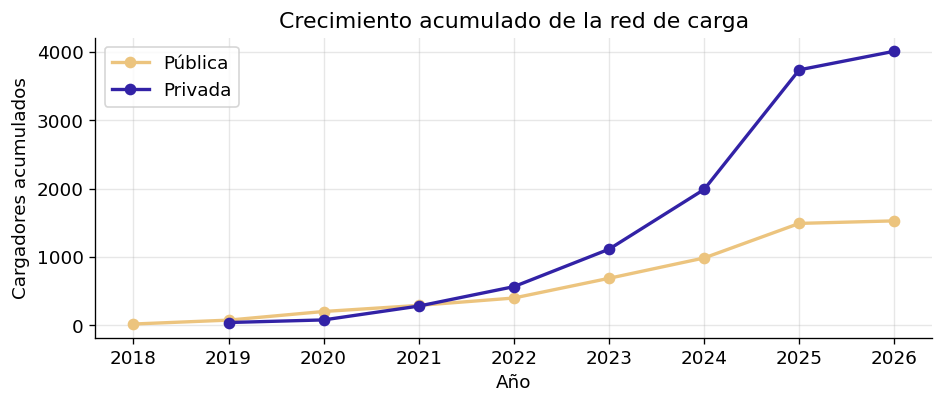

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.5))

for df, label, color in [(pub, "Pública", MAGENTA), (priv, "Privada", AZUL)]:
    por_año = df.groupby("AÑO")["CANTIDAD_CARGADORES"].sum().sort_index()
    acum    = por_año.cumsum()
    ax.plot(acum.index, acum.values, marker="o", label=label, color=color, lw=2)

ax.set_xlabel("Año")
ax.set_ylabel("Cargadores acumulados")
ax.set_title("Crecimiento acumulado de la red de carga")
ax.legend()
ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.tight_layout()
plt.show()

---
## Tarea 2 — Explorar la distribución espacial de la infraestructura

**Factibilidad:** Solo las instalaciones **públicas** incluyen coordenadas (LATITUD/LONGITUD) sin valores faltantes. Las privadas no las tienen — esto es una limitación que se debe declarar.

### 2a. Diagnóstico de coordenadas

In [7]:
print("Columnas con coordenadas en PÚBLICAS:")
print(pub[["LATITUD","LONGITUD"]].isnull().sum())
print(f"\nRango latitud  : {pub['LATITUD'].min():.4f}  a  {pub['LATITUD'].max():.4f}")
print(f"Rango longitud : {pub['LONGITUD'].min():.4f}  a  {pub['LONGITUD'].max():.4f}")
print(f"\nInstalaciones privadas con coordenadas: {'LATITUD' in priv.columns}")
print("\n⚠️  LIMITACIÓN: El análisis espacial se restringe a instalaciones públicas ({} registros).".format(len(pub)))

Columnas con coordenadas en PÚBLICAS:
LATITUD     0
LONGITUD    0
dtype: int64

Rango latitud  : -53.1661  a  -18.4628
Rango longitud : -73.8292  a  -68.1915

Instalaciones privadas con coordenadas: False

⚠️  LIMITACIÓN: El análisis espacial se restringe a instalaciones públicas (599 registros).


### 2b. Distribución por región

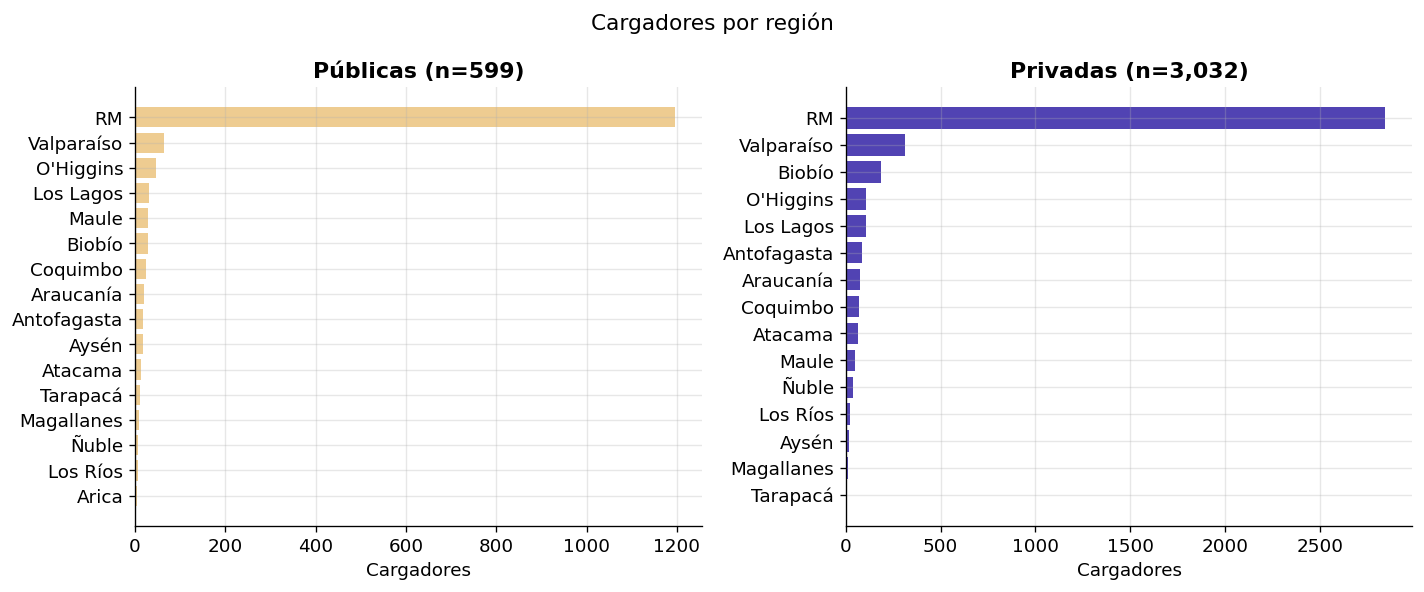

In [8]:
# Nombre corto de región para el eje
nombre_corto = {
    "Metropolitana": "RM",
    "Valparaíso": "Valparaíso",
    "Biobío": "Biobío",
    "Maule": "Maule",
    "La Araucanía": "Araucanía",
    "Los Lagos": "Los Lagos",
    "Libertador Bernardo OHiggins": "O'Higgins",
    "Ñuble": "Ñuble",
    "De los Ríos": "Los Ríos",
    "Coquimbo": "Coquimbo",
    "Antofagasta": "Antofagasta",
    "Atacama": "Atacama",
    "Aisén del General Carlos Ibáñez del Campo": "Aysén",
    "Magallanes y de la Antartica Chilena": "Magallanes",
    "Tarapacá": "Tarapacá",
    "Arica y Parinacota": "Arica",
}

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, df, titulo, color in zip(
    axes,
    [pub, priv],
    ["Públicas (n={:,})".format(len(pub)), "Privadas (n={:,})".format(len(priv))],
    [MAGENTA, AZUL]
):
    cnt = (df.groupby("REGION_INSTALACION")["CANTIDAD_CARGADORES"]
             .sum()
             .rename(index=nombre_corto)
             .sort_values(ascending=True))
    ax.barh(cnt.index, cnt.values, color=color, alpha=0.85)
    ax.set_xlabel("Cargadores")
    ax.set_title(titulo, fontweight="bold")

fig.suptitle("Cargadores por región", fontsize=13)
plt.tight_layout()
plt.show()

### 2c. Mapa de dispersión de instalaciones públicas (lat/lon)

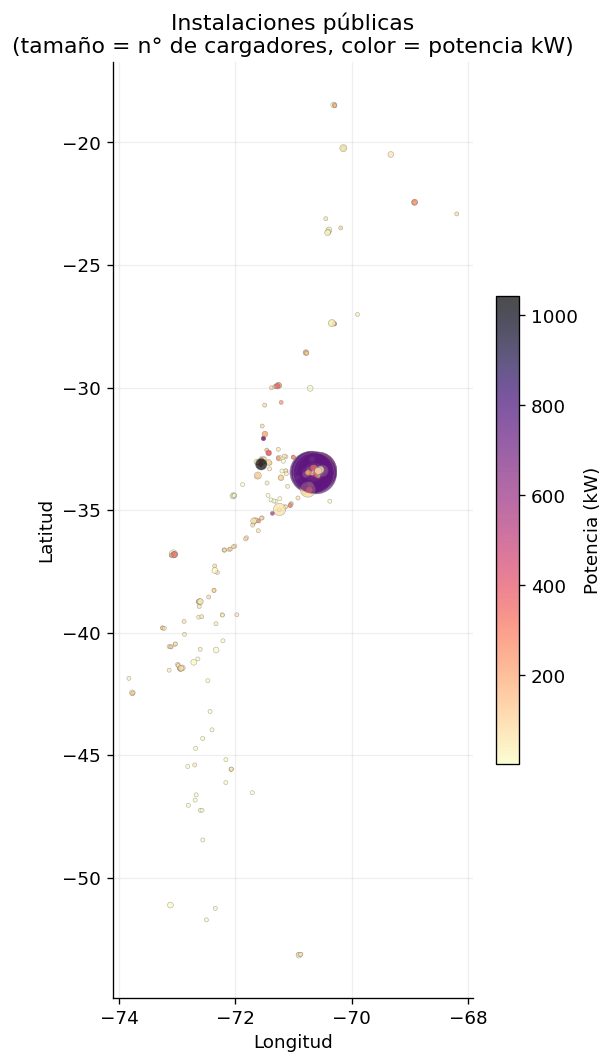


Conclusión: cobertura nacional con concentración en zona central → Tarea 2 FACTIBLE con datos públicos.


In [9]:
fig, ax = plt.subplots(figsize=(5, 9))

sc = ax.scatter(
    pub["LONGITUD"], pub["LATITUD"],
    c=pub["POTENCIA_ELECTROMOVILIDAD"],
    cmap="magma_r",
    s=pub["CANTIDAD_CARGADORES"] * 6,
    alpha=0.7,
    linewidths=0.3,
    edgecolors="gray"
)
plt.colorbar(sc, ax=ax, label="Potencia (kW)", shrink=0.5)
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
ax.set_title("Instalaciones públicas\n(tamaño = n° de cargadores, color = potencia kW)")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print("\nConclusión: cobertura nacional con concentración en zona central → Tarea 2 FACTIBLE con datos públicos.")

### 2d. Concentración en la Región Metropolitana

Instalaciones públicas en RM: 358 (59.8% del total)


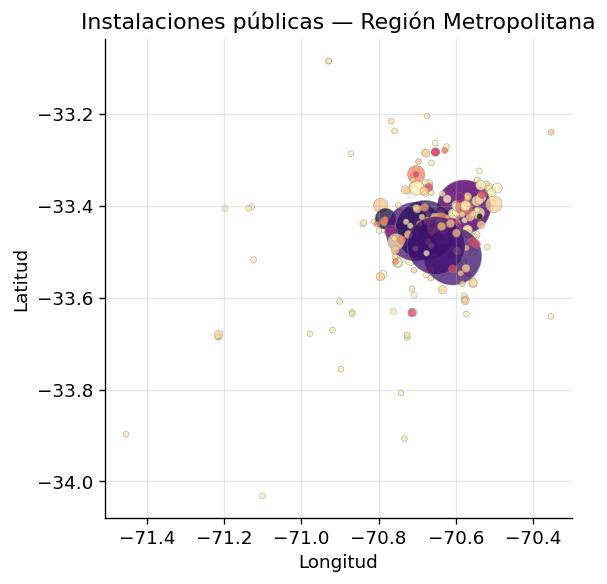

In [10]:
rm = pub[pub["REGION_INSTALACION"] == "Metropolitana"].copy()
print(f"Instalaciones públicas en RM: {len(rm)} ({100*len(rm)/len(pub):.1f}% del total)")

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(
    rm["LONGITUD"], rm["LATITUD"],
    c=rm["POTENCIA_ELECTROMOVILIDAD"],
    cmap="magma_r",
    s=rm["CANTIDAD_CARGADORES"] * 12,
    alpha=0.75,
    edgecolors="gray", linewidths=0.3
)
ax.set_title("Instalaciones públicas — Región Metropolitana")
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
plt.tight_layout()
plt.show()

---
## Tarea 3 — Analizar la separación entre puntos de carga

**Factibilidad:** Con coordenadas de las instalaciones públicas se puede calcular la distancia al vecino más cercano. Se usa distancia haversine (sobre esfera) para obtener km reales.

### 3a. Función de distancia haversine

In [11]:
def haversine_km(lat1, lon1, lat2, lon2):
    """Distancia en km entre dos puntos (grados decimales)."""
    R = 6371.0
    phi1, phi2 = np.radians(lat1), np.radians(lat2)
    dphi  = np.radians(lat2 - lat1)
    dlam  = np.radians(lon2 - lon1)
    a = np.sin(dphi/2)**2 + np.cos(phi1)*np.cos(phi2)*np.sin(dlam/2)**2
    return 2 * R * np.arcsin(np.sqrt(a))

# Verificación rápida: Santiago → Valparaíso ≈ 100 km
d_test = haversine_km(-33.45, -70.65, -33.05, -71.61)
print(f"Santiago → Valparaíso : {d_test:.1f} km  (referencia ≈ 100 km)")

Santiago → Valparaíso : 99.7 km  (referencia ≈ 100 km)


### 3b. Distancia al vecino más cercano (NN) entre instalaciones públicas

In [12]:
coords_rad = np.radians(pub[["LATITUD", "LONGITUD"]].values)

# cKDTree en coordenadas cartesianas proyectadas (aproximación esférica)
# Para mayor precisión usamos conversión a xyz en la esfera unitaria
def latlon_to_xyz(lat_rad, lon_rad):
    x = np.cos(lat_rad) * np.cos(lon_rad)
    y = np.cos(lat_rad) * np.sin(lon_rad)
    z = np.sin(lat_rad)
    return np.column_stack([x, y, z])

xyz = latlon_to_xyz(coords_rad[:, 0], coords_rad[:, 1])
tree = cKDTree(xyz)

# k=2: el primer resultado es la propia instalación (distancia 0)
dists_chord, _ = tree.query(xyz, k=2)
dist_chord_nn  = dists_chord[:, 1]  # distancia al vecino más cercano

# Convertir distancia de cuerda a km: d_km = 2 * R * arcsin(chord/2)
R = 6371.0
dist_km_nn = 2 * R * np.arcsin(dist_chord_nn / 2)

pub["DIST_NN_KM"] = dist_km_nn

print("Distancia al vecino más cercano (km):")
print(pd.Series(dist_km_nn).describe().round(2))

Distancia al vecino más cercano (km):
count    599.00
mean       4.41
std       12.81
min        0.00
25%        0.20
50%        0.58
75%        1.58
max      134.65
dtype: float64


### 3c. Distribución de la separación entre instalaciones

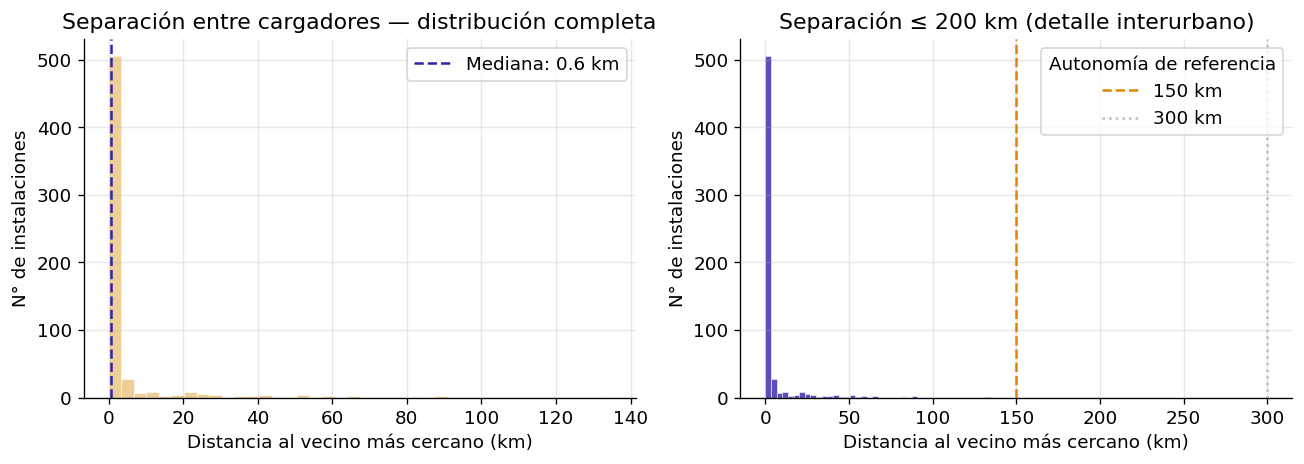

Instalaciones con NN > 150 km: 0 (0.0%)
Instalaciones con NN > 300 km: 0 (0.0%)

Conclusión: la separación tiene variabilidad relevante → Tarea 3 FACTIBLE.


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Histograma completo
ax = axes[0]
ax.hist(dist_km_nn, bins=40, color=MAGENTA, alpha=0.8, edgecolor="white", linewidth=0.4)
ax.set_xlabel("Distancia al vecino más cercano (km)")
ax.set_ylabel("N° de instalaciones")
ax.set_title("Separación entre cargadores — distribución completa")
ax.axvline(np.median(dist_km_nn), color=AZUL, lw=1.5, linestyle="--", label=f"Mediana: {np.median(dist_km_nn):.1f} km")
ax.legend()

# Zoom en zona ≤ 200 km (interurbano relevante)
ax = axes[1]
mask = dist_km_nn <= 200
ax.hist(dist_km_nn[mask], bins=40, color=AZUL, alpha=0.8, edgecolor="white", linewidth=0.4)
ax.set_xlabel("Distancia al vecino más cercano (km)")
ax.set_ylabel("N° de instalaciones")
ax.set_title("Separación ≤ 200 km (detalle interurbano)")
# Líneas de referencia de autonomía
for autonomia, color_ref, ls in [(150, NARANJA, "--"), (300, GRIS, ":")]:
    ax.axvline(autonomia, color=color_ref, lw=1.5, linestyle=ls, label=f"{autonomia} km")
ax.legend(title="Autonomía de referencia")

plt.tight_layout()
plt.show()

print(f"Instalaciones con NN > 150 km: {(dist_km_nn > 150).sum()} ({100*(dist_km_nn > 150).mean():.1f}%)")
print(f"Instalaciones con NN > 300 km: {(dist_km_nn > 300).sum()} ({100*(dist_km_nn > 300).mean():.1f}%)")
print("\nConclusión: la separación tiene variabilidad relevante → Tarea 3 FACTIBLE.")

### 3d. Separación por región

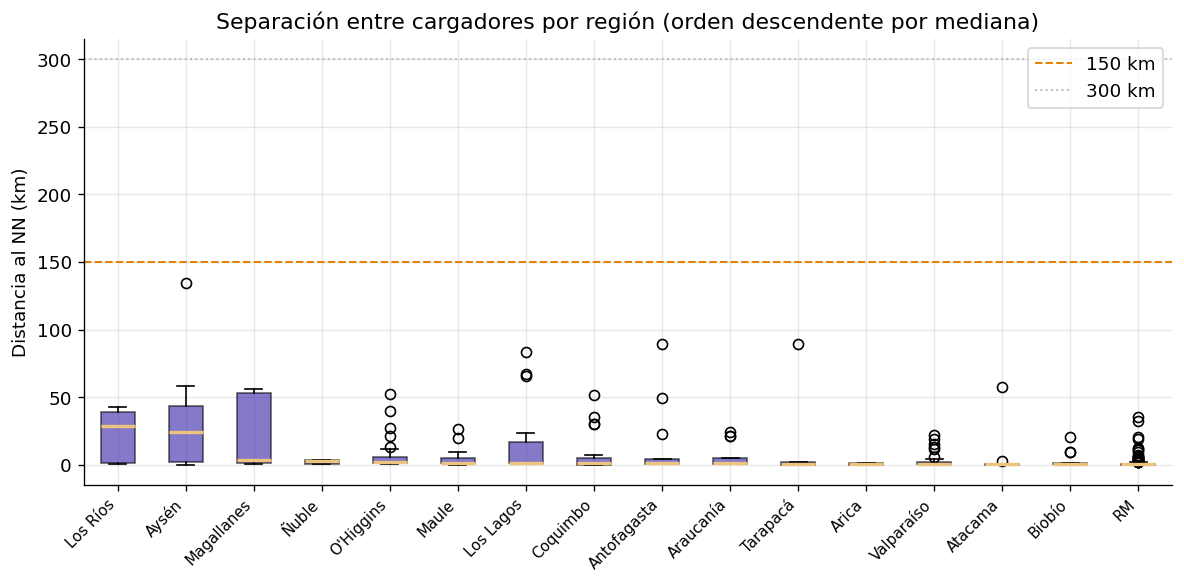

In [14]:
pub["REGION_CORTA"] = pub["REGION_INSTALACION"].map(nombre_corto).fillna(pub["REGION_INSTALACION"])

orden_mediana = (pub.groupby("REGION_CORTA")["DIST_NN_KM"]
                    .median()
                    .sort_values(ascending=False)
                    .index)

fig, ax = plt.subplots(figsize=(10, 5))
data_box = [pub.loc[pub["REGION_CORTA"] == r, "DIST_NN_KM"].values for r in orden_mediana]
bp = ax.boxplot(data_box, vert=True, patch_artist=True,
                medianprops=dict(color=MAGENTA, linewidth=2))
for patch in bp["boxes"]:
    patch.set_facecolor(AZUL)
    patch.set_alpha(0.6)

ax.set_xticks(range(1, len(orden_mediana)+1))
ax.set_xticklabels(orden_mediana, rotation=45, ha="right", fontsize=9)
ax.set_ylabel("Distancia al NN (km)")
ax.set_title("Separación entre cargadores por región (orden descendente por mediana)")
ax.axhline(150, color=NARANJA, lw=1.2, ls="--", label="150 km")
ax.axhline(300, color=GRIS,   lw=1.2, ls=":",  label="300 km")
ax.legend()
plt.tight_layout()
plt.show()

---
## Tarea 4 — Comparar separaciones con distintos rangos de autonomía

**Factibilidad:** Con las distancias calculadas en Tarea 3, se puede clasificar cada tramo como accesible o no para distintos rangos de autonomía.

### 4a. Rangos de autonomía representativos

In [15]:
# Vehículos eléctricos de referencia (autonomía WLTP aproximada)
autonomias = {
    "Urbano (150 km)": 150,
    "Compacto (250 km)": 250,
    "Estándar (350 km)": 350,
    "Premium (500 km)": 500,
}

# Para cada autonomía: ¿qué fracción de instalaciones tiene su NN dentro del rango?
# Se asume que el vehículo puede recorrer hasta 80% de la autonomía antes de recargar
factores_uso = [0.5, 0.6, 0.7, 0.8]  # fracción de autonomía antes de recargar

print("Fracción de instalaciones con vecino más cercano ACCESIBLE por autonomía y factor de uso\n")
header = "Autonomía          " + "  ".join(f"  {int(f*100)}%" for f in factores_uso)
print(header)
print("-" * len(header))

tabla_acceso = {}
for label, km in autonomias.items():
    row = []
    for f in factores_uso:
        umbral = km * f
        frac   = (dist_km_nn <= umbral).mean()
        row.append(frac)
    tabla_acceso[label] = row
    fila = f"{label:<22}" + "   ".join(f"{v:.1%}" for v in row)
    print(fila)

Fracción de instalaciones con vecino más cercano ACCESIBLE por autonomía y factor de uso

Autonomía            50%    60%    70%    80%
---------------------------------------------
Urbano (150 km)       99.3%   99.8%   99.8%   99.8%
Compacto (250 km)     99.8%   100.0%   100.0%   100.0%
Estándar (350 km)     100.0%   100.0%   100.0%   100.0%
Premium (500 km)      100.0%   100.0%   100.0%   100.0%


### 4b. Visualización: accesibilidad por autonomía y factor de uso

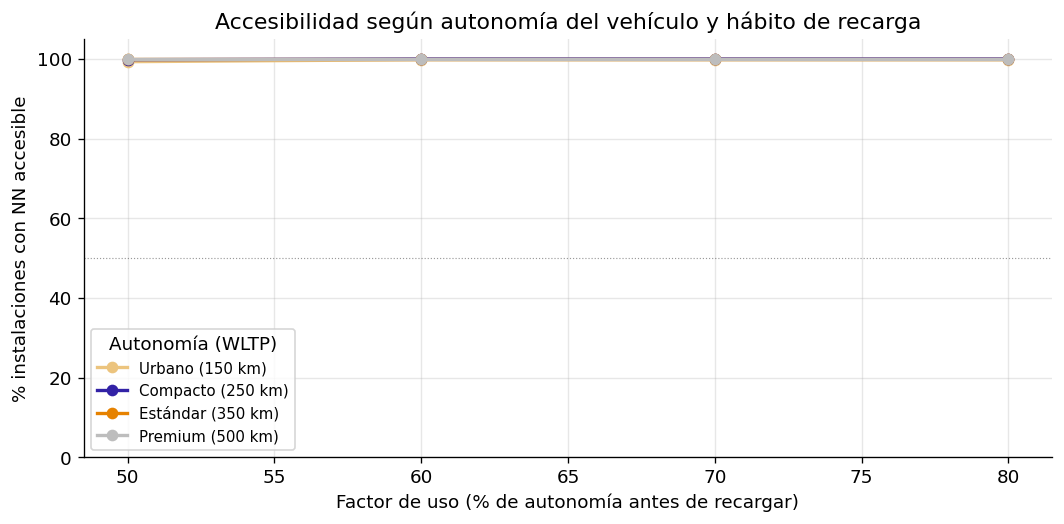


Conclusión: se puede comparar accesibilidad para distintos perfiles de VE → Tarea 4 FACTIBLE.


In [16]:
fig, ax = plt.subplots(figsize=(9, 4.5))

colores_linea = [MAGENTA, AZUL, NARANJA, GRIS]

for (label, row), color in zip(tabla_acceso.items(), colores_linea):
    ax.plot([f * 100 for f in factores_uso], [v * 100 for v in row],
            marker="o", lw=2, color=color, label=label)

ax.set_xlabel("Factor de uso (% de autonomía antes de recargar)")
ax.set_ylabel("% instalaciones con NN accesible")
ax.set_title("Accesibilidad según autonomía del vehículo y hábito de recarga")
ax.legend(title="Autonomía (WLTP)", fontsize=9)
ax.set_ylim(0, 105)
ax.axhline(50, color="black", lw=0.7, ls=":", alpha=0.4)
plt.tight_layout()
plt.show()

print("\nConclusión: se puede comparar accesibilidad para distintos perfiles de VE → Tarea 4 FACTIBLE.")

### 4c. Mapa de accesibilidad: instalaciones con NN > umbral

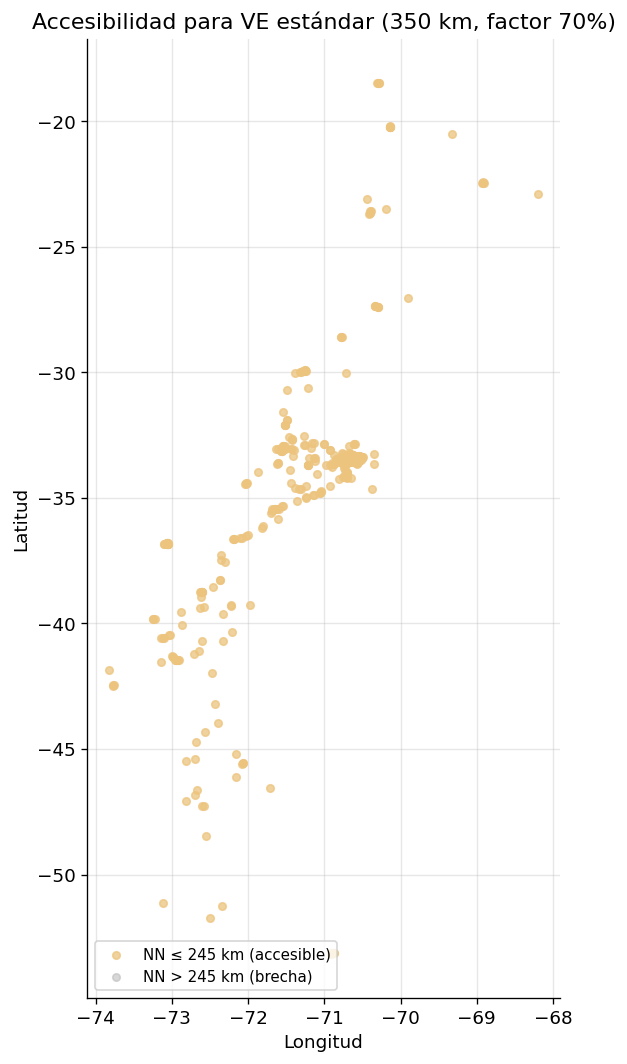

In [17]:
# Para autonomía estándar (350 km) con factor 70% → umbral = 245 km
AUTONOMIA_REF = 350
FACTOR_REF    = 0.70
UMBRAL        = AUTONOMIA_REF * FACTOR_REF

accesible     = pub["DIST_NN_KM"] <= UMBRAL

fig, ax = plt.subplots(figsize=(5, 9))

ax.scatter(
    pub.loc[accesible, "LONGITUD"],
    pub.loc[accesible, "LATITUD"],
    color=MAGENTA, alpha=0.75, s=20, label=f"NN ≤ {UMBRAL:.0f} km (accesible)",
    zorder=3
)
ax.scatter(
    pub.loc[~accesible, "LONGITUD"],
    pub.loc[~accesible, "LATITUD"],
    color=GRIS, alpha=0.6, s=20, label=f"NN > {UMBRAL:.0f} km (brecha)",
    zorder=2
)

ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
ax.set_title(f"Accesibilidad para VE estándar ({AUTONOMIA_REF} km, factor {int(FACTOR_REF*100)}%)")
ax.legend(loc="lower left", fontsize=9)
plt.tight_layout()
plt.show()

---
## Resumen de factibilidad

In [18]:
resumen_factibilidad = pd.DataFrame({
    "Tarea": [
        "1. Caracterizar cantidad y capacidad",
        "2. Distribución espacial",
        "3. Separación entre puntos de carga",
        "4. Comparar con rangos de autonomía",
    ],
    "Variables usadas": [
        "CANTIDAD_CARGADORES, POTENCIA_ELECTROMOVILIDAD",
        "LATITUD, LONGITUD (solo públicas)",
        "LATITUD, LONGITUD → distancia haversine NN",
        "DIST_NN_KM + umbrales de autonomía definidos",
    ],
    "Valores faltantes": ["0 / 3631", "0 / 599", "0 / 599", "N/A (derivada)"],
    "Factible": ["✅ Sí", "✅ Sí (con limitación)", "✅ Sí", "✅ Sí"],
    "Limitación": [
        "Privadas sin coordenadas, solo cantidad/potencia",
        "Privadas sin lat/lon: solo distribución por región/comuna",
        "Basado únicamente en instalaciones públicas",
        "Autonomías son WLTP estimadas, no mediciones reales",
    ]
})

print(resumen_factibilidad.to_string(index=False))

                               Tarea                               Variables usadas Valores faltantes              Factible                                                Limitación
1. Caracterizar cantidad y capacidad CANTIDAD_CARGADORES, POTENCIA_ELECTROMOVILIDAD          0 / 3631                  ✅ Sí          Privadas sin coordenadas, solo cantidad/potencia
            2. Distribución espacial              LATITUD, LONGITUD (solo públicas)           0 / 599 ✅ Sí (con limitación) Privadas sin lat/lon: solo distribución por región/comuna
 3. Separación entre puntos de carga     LATITUD, LONGITUD → distancia haversine NN           0 / 599                  ✅ Sí               Basado únicamente en instalaciones públicas
 4. Comparar con rangos de autonomía   DIST_NN_KM + umbrales de autonomía definidos    N/A (derivada)                  ✅ Sí       Autonomías son WLTP estimadas, no mediciones reales


---
## Hito 3 — Visualización global

**Pregunta (propuesta):** ¿qué zonas y trayectos pueden conectarse mediante cargadores rápidos según la autonomía?

**Estrategia de reducción de complejidad:** filtrar (cargadores >50 kW), derivar (red mínima y brechas), facetar (3 autonomías), agregar (barras por región) y hacer zoom (Santiago).

Las celdas siguientes reutilizan `pub`, `priv` y `haversine_km` definidos arriba: ejecuta el notebook en orden.

### H3a. Parámetros y red de cargadores rápidos

In [46]:
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import minimum_spanning_tree, connected_components
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# ---------- Parámetros del Hito 3 (se pueden cambiar) ----------
UMBRAL_RAPIDO = 50      # kW: "cargador rápido" = instalación con potencia > 50 kW
FACTOR_USO    = 0.70    # fracción de la autonomía que se usa antes de recargar
ESCENARIOS    = [200, 300, 400]   # autonomías (km) de cada mapa
ESC_BARRAS    = 300               # escenario que colorea las barras por región
RUTA_PNG      = "hito3_visualizacion_global_solo_chile_anotado_FINAL.png"

# Paleta Okabe-Ito (distinguible con daltonismo)
C_CONECT = "#0072B2"   # azul: conectado a la red principal
C_AISLA  = "#D55E00"   # bermellón: aislado / brecha
C_OTRAS  = "#B8BEC6"   # gris: otras públicas (contexto)
C_PRIV   = "#CC79A7"   # rosa: privadas
C_TXT, C_SUAVE = "#1f2933", "#5f6b7a"

REGIONES = ["Arica y Parinacota","Tarapacá","Antofagasta","Atacama","Coquimbo","Valparaíso",
            "Metropolitana","Libertador Bernardo OHiggins","Maule","Ñuble","Biobío","La Araucanía",
            "De los Ríos","Los Lagos","Aisén del General Carlos Ibáñez del Campo",
            "Magallanes y de la Antartica Chilena"]
REG_CORTO = ["Arica y Parinacota","Tarapacá","Antofagasta","Atacama","Coquimbo","Valparaíso",
             "Metropolitana","O’Higgins","Maule","Ñuble","Biobío","La Araucanía","Los Ríos",
             "Los Lagos","Aysén","Magallanes"]
CIUDADES = [("Arica",-18.48),("Iquique",-20.21),("Antofagasta",-23.65),("Copiapó",-27.37),
            ("La Serena",-29.90),("Santiago",-33.45),("Concepción",-36.83),("Temuco",-38.74),
            ("Puerto Montt",-41.47),("Coyhaique",-45.57),("Punta Arenas",-53.16)]

# ---------- Red de cargadores rápidos ----------
pub_h3 = pub.copy()
pub_h3["RAPIDO"] = pub_h3["POTENCIA_ELECTROMOVILIDAD"] > UMBRAL_RAPIDO
rapidos = pub_h3[pub_h3["RAPIDO"]].reset_index(drop=True)
otras   = pub_h3[~pub_h3["RAPIDO"]].reset_index(drop=True)
n_rap   = len(rapidos)

# Matriz de distancias haversine (km) entre cargadores rápidos (usa haversine_km de la Tarea 3)
la, lo = rapidos["LATITUD"].values, rapidos["LONGITUD"].values
D = haversine_km(la[:, None], lo[:, None], la[None, :], lo[None, :])
np.fill_diagonal(D, 0)

# Árbol de expansión mínima: dos cargadores quedan conectados con alcance R
# si y solo si el camino entre ellos en el árbol no tiene aristas > R.
mst = minimum_spanning_tree(csr_matrix(D)).tocoo()
aristas = list(zip(mst.data, mst.row, mst.col))

def escenario(R):
    """Devuelve (máscara de la red principal, nº de componentes) para un alcance útil R (km)."""
    ok = [(i, j) for w, i, j in aristas if w <= R]
    A = csr_matrix((np.ones(len(ok)), ([k[0] for k in ok], [k[1] for k in ok])), shape=(n_rap, n_rap))
    nc, lab = connected_components(A, directed=False)
    return lab == np.bincount(lab).argmax(), nc

for a in ESCENARIOS:
    m, nc = escenario(a * FACTOR_USO)
    print(f"Autonomía {a} km (alcance útil {a*FACTOR_USO:.0f} km): {m.sum()} de {n_rap} en la red principal, {nc-1} tramos aislados")
print("\nBrechas más largas entre cargadores rápidos (km, línea recta):")
for w, i, j in sorted(aristas, reverse=True)[:6]:
    print(f"  {w:5.0f} km  {rapidos.COMUNA_INSTALACION[i]} ↔ {rapidos.COMUNA_INSTALACION[j]}")

Autonomía 200 km (alcance útil 140 km): 233 de 253 en la red principal, 7 tramos aislados
Autonomía 300 km (alcance útil 210 km): 238 de 253 en la red principal, 4 tramos aislados
Autonomía 400 km (alcance útil 280 km): 238 de 253 en la red principal, 3 tramos aislados

Brechas más largas entre cargadores rápidos (km, línea recta):
    843 km  Punta Arenas ↔ Coyhaique
    419 km  Antofagasta ↔ Copiapó
    372 km  Castro ↔ Coyhaique
    220 km  Pica ↔ Calama
    193 km  Arica ↔ Iquique
    172 km  Calama ↔ Mejillones


### H3b. Figura final (se guarda como PNG)

Columnas regiones: ['objectid', 'cir_sena', 'codregion', 'area_km', 'st_area_sh', 'st_length_', 'Region', 'geometry']
Columnas comunas : ['FID', 'OBJECTID', 'REGION', 'PROVINCIA', 'COMUNA', 'DESC_REGIO', 'DESC_PROVI', 'DESC_COMUN', 'Shape_Leng', 'Shape_Area', 'Shape__Area', 'Shape__Length', 'geometry']
Comunas de los Excel sin polígono (revisar nombres): ['lascondes', 'lobarnechea', 'colina', 'vitacura', 'providencia', 'penalolen', 'maipu', 'pudahuel', 'nunoa', 'huechuraba', 'laflorida', 'lareina', 'quilicura', 'puentealto', 'santiago', 'sanbernardo', 'macul', 'lampa', 'estacioncentral', 'cerrillos', 'buin', 'renca', 'recoleta', 'sanmiguel', 'padrehurtado', 'independencia', 'sanjoaquin', 'conchali', 'quintanormal', 'lacisterna', 'lagranja', 'talagante', 'melipilla', 'loprado', 'caleradetango', 'tiltil', 'curacavi', 'islademaipo', 'cerronavia', 'pirque', 'penaflor', 'elbosque', 'pedroaguirrecerda', 'paine', 'mariapinto', 'lapintana', 'loespejo', 'elmonte', 'sanramon', 'alhue', 'sanjosed

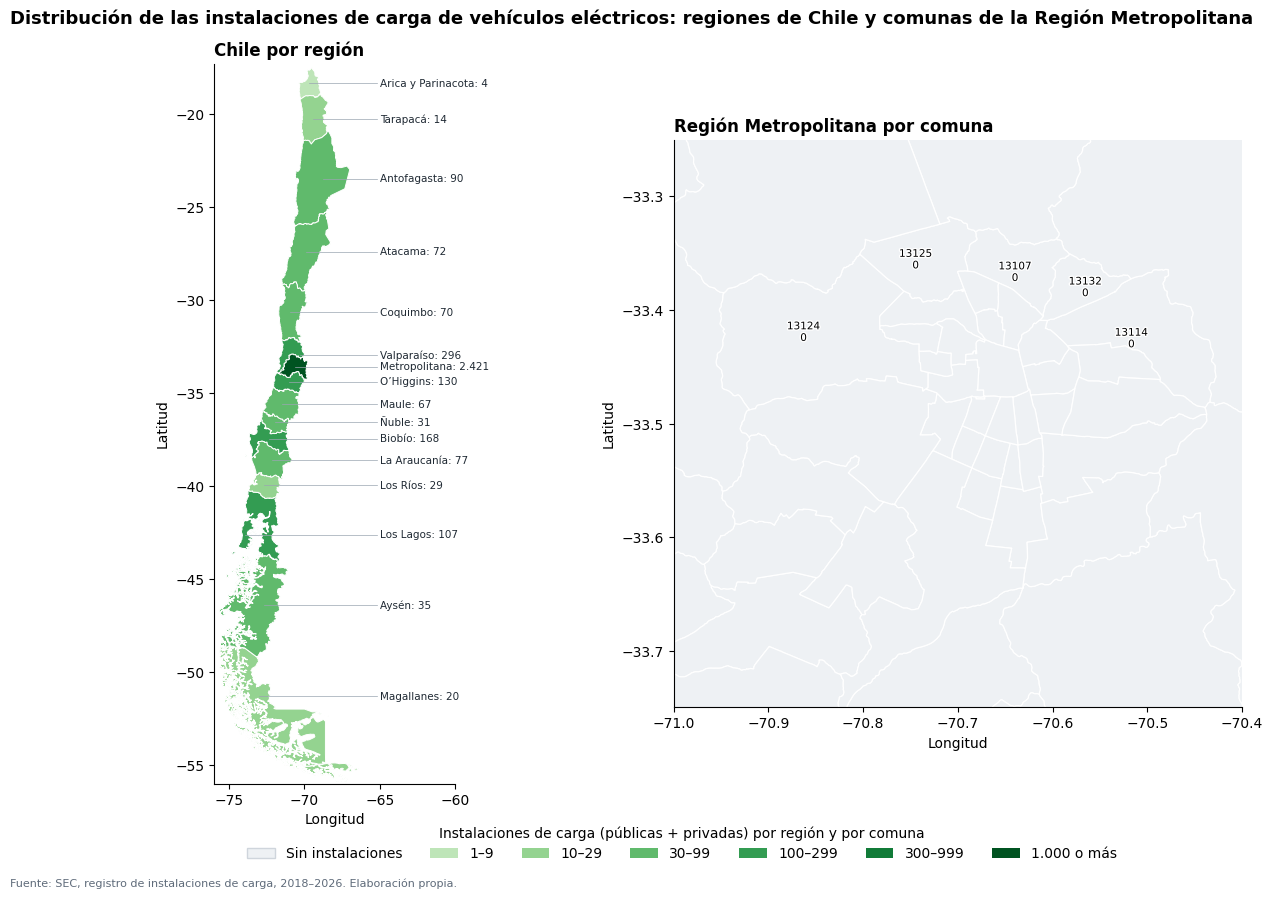

In [27]:
import re, unicodedata
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import matplotlib.patheffects as pe

# =====================  EDITAR AQUÍ  =====================
# Regiones de Chile: URL GeoJSON (repositorio caracena/chile-geojson) o ruta a un archivo local (.shp/.geojson)
FUENTE_REGIONES = "https://raw.githubusercontent.com/caracena/chile-geojson/master/regiones.json"
# Comunas de la RM: la capa de ArcGIS que encontraste (o un archivo local)
FUENTE_COMUNAS = ("https://services.arcgis.com/JZxvGBwvCaXCwa4l/ArcGIS/rest/services/"
                  "Comunas_Regi%C3%B3n_Metropolitana/FeatureServer/0/query"
                  "?where=1%3D1&outFields=*&outSR=4326&f=geojson")
SOLO_GRAN_SANTIAGO = True      # True: recorta al área urbana; False: toda la RM
# =========================================================

# ---------- utilidades de nombres ----------
def norm(s):
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode().lower()
    return re.sub(r"[^a-z]", "", s)

TOKENS = [("arica","arica"),("tarapaca","tarapaca"),("antofagasta","antofagasta"),("atacama","atacama"),
          ("coquimbo","coquimbo"),("valparaiso","valparaiso"),("metropolitana","metropolitana"),
          ("higgins","higgins"),("maule","maule"),("nuble","nuble"),("biobio","biobio"),
          ("araucania","araucania"),("rios","rios"),("lagos","lagos"),("aisen","aysen"),
          ("aysen","aysen"),("magallanes","magallanes")]
def clave_region(nombre):
    n = norm(nombre)
    return next((c for t, c in TOKENS if t in n), n)

NOMBRE_CORTO = {"arica":"Arica y Parinacota","tarapaca":"Tarapacá","antofagasta":"Antofagasta","atacama":"Atacama",
                "coquimbo":"Coquimbo","valparaiso":"Valparaíso","metropolitana":"Metropolitana","higgins":"O’Higgins",
                "maule":"Maule","nuble":"Ñuble","biobio":"Biobío","araucania":"La Araucanía","rios":"Los Ríos",
                "lagos":"Los Lagos","aysen":"Aysén","magallanes":"Magallanes"}

def columna(gdf, candidatas):
    bajo = {c.lower(): c for c in gdf.columns}
    for c in candidatas:
        if c.lower() in bajo: return bajo[c.lower()]
    raise KeyError(f"No encuentro la columna de nombre. Columnas disponibles: {list(gdf.columns)}")

# ---------- conteo de instalaciones (públicas + privadas) ----------
todas = pd.concat([pub[["REGION_INSTALACION", "COMUNA_INSTALACION"]],
                   priv[["REGION_INSTALACION", "COMUNA_INSTALACION"]]], ignore_index=True)
todas["REG"] = todas["REGION_INSTALACION"].map(clave_region)
tot_reg = todas["REG"].value_counts()
tot_com = todas.loc[todas["REG"] == "metropolitana", "COMUNA_INSTALACION"].map(norm).value_counts()

# ---------- escala de color: secuencial, una tonalidad, clases ----------
LIMITES   = [1, 10, 30, 100, 300, 1000, 3000]
ETIQUETAS = ["1–9", "10–29", "30–99", "100–299", "300–999", "1.000 o más"]
COLORES   = [plt.cm.Greens(v) for v in np.linspace(.28, .95, 6)]
COL_CERO  = "#eef1f4"
def color_cuenta(n):
    if n < 1: return COL_CERO
    return COLORES[min(int(np.searchsorted(LIMITES, n, side="right")) - 1, 5)]

# ---------- cargar geometrías ----------
g_reg = gpd.read_file(FUENTE_REGIONES)
g_com = gpd.read_file(FUENTE_COMUNAS)
if g_reg.crs is not None: g_reg = g_reg.to_crs(4326)
if g_com.crs is not None: g_com = g_com.to_crs(4326)
print("Columnas regiones:", list(g_reg.columns)); print("Columnas comunas :", list(g_com.columns))
COL_REG = columna(g_reg, ["Region", "NOM_REG", "NOM_REGION", "REGION", "NOMBRE", "name"])
COL_COM = columna(g_com, ["Comuna", "NOM_COMUNA", "NOM_COM", "COMUNA", "NAME", "NOMBRE", "name"])

g_reg["clave"] = g_reg[COL_REG].map(clave_region)
g_reg["n"]     = g_reg["clave"].map(tot_reg).fillna(0)
g_reg["geometry"] = g_reg.geometry.simplify(0.01)            # más liviano de dibujar
g_com["clave"] = g_com[COL_COM].map(norm)
g_com["n"]     = g_com["clave"].map(tot_com).fillna(0)
faltan = [c for c in tot_com.index if c not in set(g_com["clave"])]
if faltan: print("Comunas de los Excel sin polígono (revisar nombres):", faltan)

# ---------- figura ----------
plt.rcdefaults()
plt.rcParams.update({"font.family": "DejaVu Sans", "axes.spines.top": False, "axes.spines.right": False})
fig, (axC, axS) = plt.subplots(1, 2, figsize=(14, 9), gridspec_kw={"width_ratios": [1, 1.6]})

# --- Chile por región ---
g_reg.plot(ax=axC, color=[color_cuenta(n) for n in g_reg["n"]], edgecolor="white", linewidth=.7)
XMIN, XMAX, YMIN, YMAX = -76, -65.5, -56, -17.3             # solo Chile continental
axC.set_xlim(XMIN, XMAX + 5.5); axC.set_ylim(YMIN, YMAX)
axC.set_aspect(1 / np.cos(np.radians(36)))
for _, fila in g_reg.iterrows():                            # etiquetas con línea guía a la derecha
    p = fila.geometry.representative_point()
    if not (XMIN < p.x < XMAX and YMIN < p.y < YMAX): continue
    axC.plot([p.x, XMAX + .3], [p.y, p.y], color="#9aa5b1", lw=.5, zorder=1)
    axC.text(XMAX + .5, p.y, f"{NOMBRE_CORTO.get(fila['clave'], fila[COL_REG])}: {int(fila['n']):,}".replace(",", "."),
             fontsize=7.5, va="center", color="#1f2933")
axC.set_title("Chile por región", fontweight="bold", loc="left")
axC.set_xlabel("Longitud"); axC.set_ylabel("Latitud")

# --- Santiago por comuna ---
g_com.plot(ax=axS, color=[color_cuenta(n) for n in g_com["n"]], edgecolor="white", linewidth=.9)
if SOLO_GRAN_SANTIAGO:
    axS.set_xlim(-71.0, -70.40); axS.set_ylim(-33.75, -33.25)
axS.set_aspect(1 / np.cos(np.radians(33.45)))
for _, fila in g_com.sort_values("n", ascending=False).head(6).iterrows():   # las 6 comunas con más instalaciones
    p = fila.geometry.representative_point()
    if axS.get_xlim()[0] < p.x < axS.get_xlim()[1] and axS.get_ylim()[0] < p.y < axS.get_ylim()[1]:
        axS.text(p.x, p.y, f"{fila[COL_COM]}\n{int(fila['n'])}", ha="center", va="center", fontsize=7.5,
                 path_effects=[pe.withStroke(linewidth=2, foreground="white")])
axS.set_title("Región Metropolitana por comuna", fontweight="bold", loc="left")
axS.set_xlabel("Longitud"); axS.set_ylabel("Latitud")

# --- leyenda común, título y fuente ---
hs = [Patch(fc=COL_CERO, ec="#cfd5dc")] + [Patch(fc=c) for c in COLORES]
fig.legend(hs, ["Sin instalaciones"] + ETIQUETAS, loc="lower center", ncol=7, frameon=False,
           title="Instalaciones de carga (públicas + privadas) por región y por comuna", bbox_to_anchor=(.5, .02))
fig.suptitle("Distribución de las instalaciones de carga de vehículos eléctricos: regiones de Chile y comunas de la Región Metropolitana",
             fontsize=13, fontweight="bold", x=.02, ha="left")
fig.text(.02, .005, "Fuente: SEC, registro de instalaciones de carga, 2018–2026. Elaboración propia.", fontsize=8, color="#5f6b7a")
fig.subplots_adjust(top=.92, bottom=.12, wspace=.35)
fig.savefig("mapas_chile_santiago.png", dpi=220, facecolor="white")
plt.show()

Guardado: hito3_visualizacion_global.png


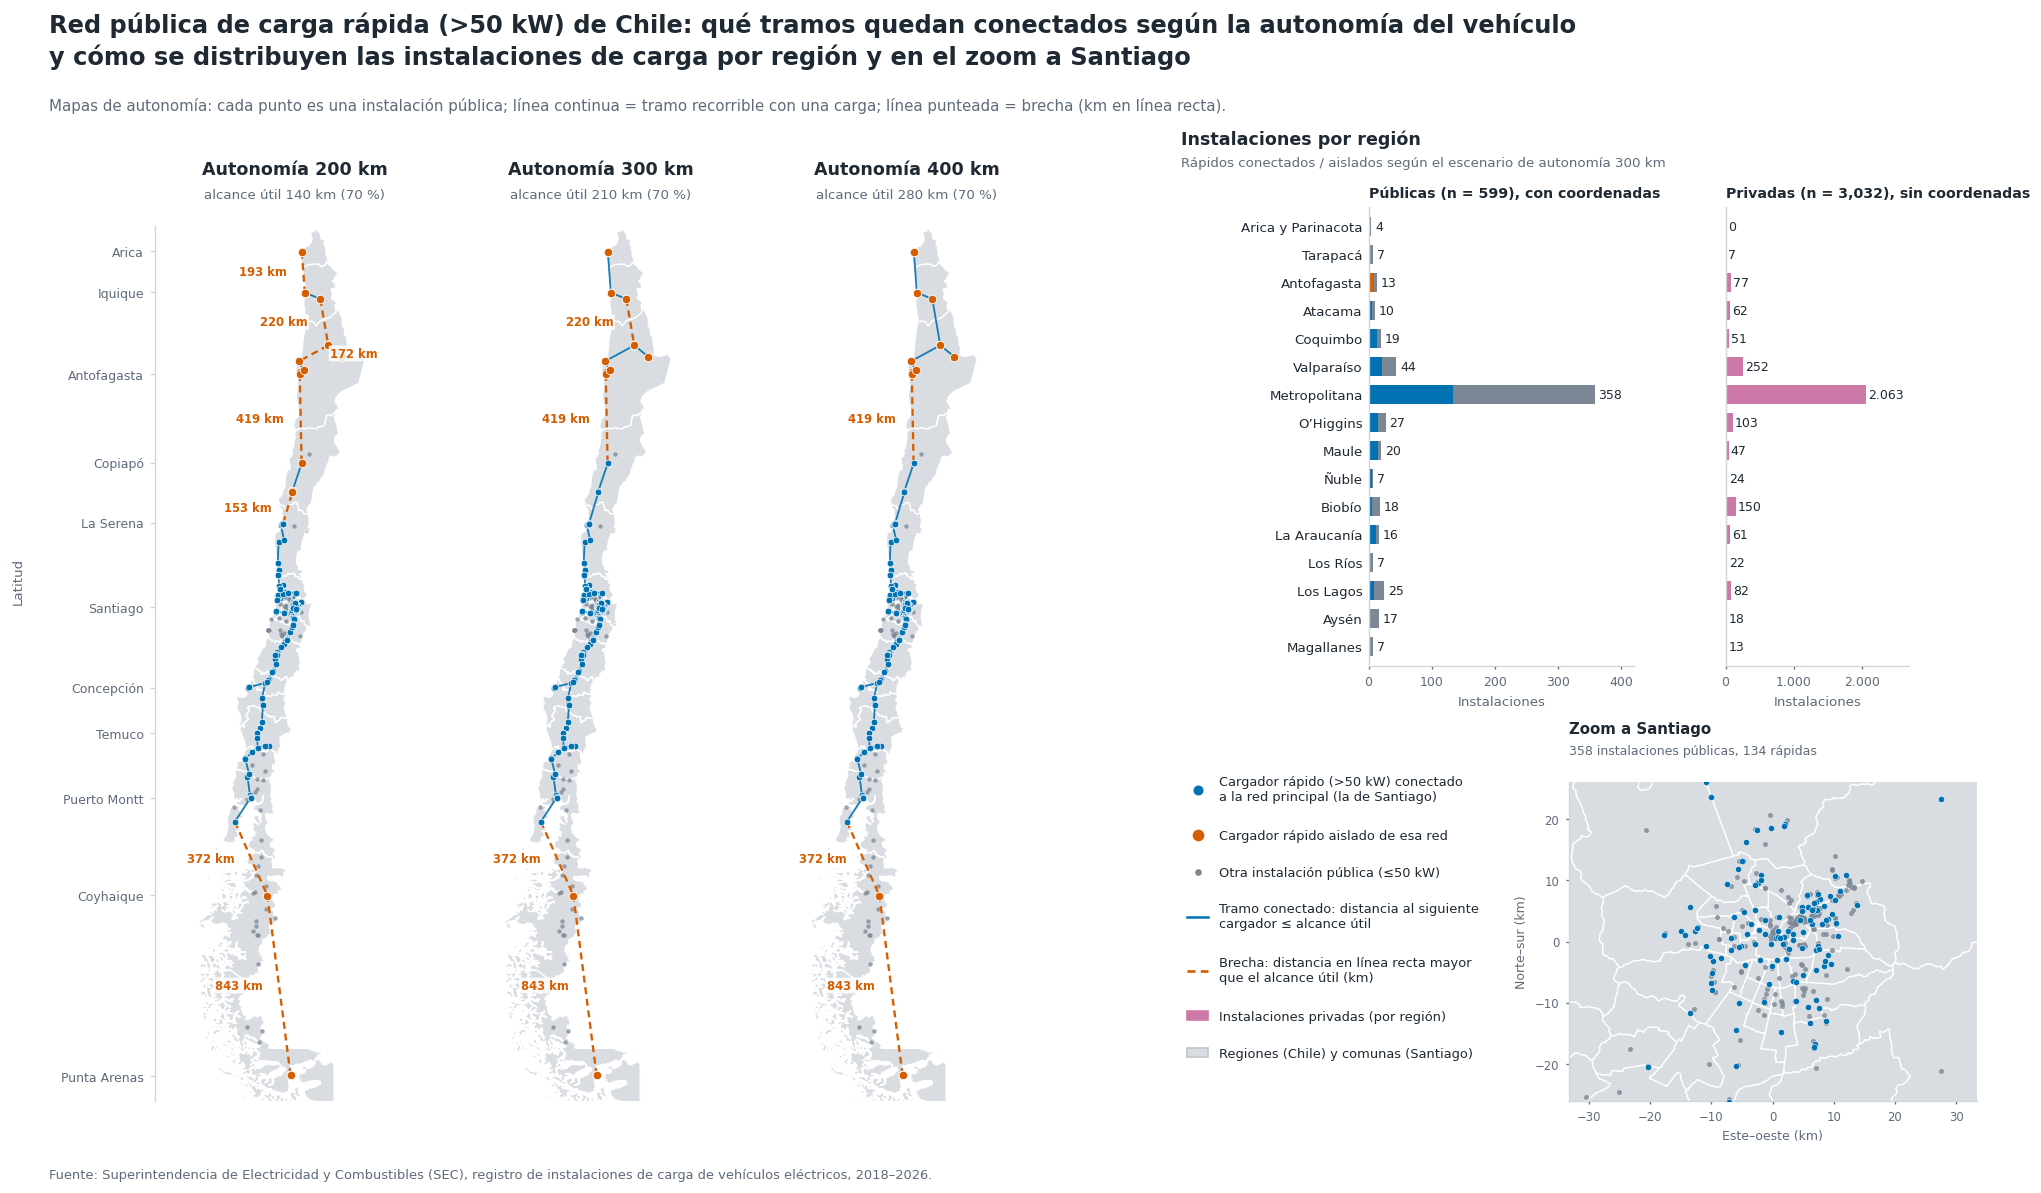

In [43]:
# Requiere haber ejecutado antes: la celda de la red (H3a) y la celda de mapas (mapas_chile_santiago),
# que dejan definidos g_reg, g_com, COL_REG, COL_COM, norm
assert all(v in globals() for v in ["g_reg", "g_com", "COL_REG", "COL_COM", "norm", "escenario"]), \
    "Ejecuta primero la celda H3a (red) y la celda mapas_chile_santiago (geometrías)."

import matplotlib.patheffects as pe
from matplotlib.path import Path
from matplotlib.patches import PathPatch

plt.rcdefaults()
plt.rcParams.update({"font.family": "DejaVu Sans", "axes.grid": False,
                     "axes.spines.top": False, "axes.spines.right": False})

# ---------- textos (editables; pon "" para ocultar) ----------
TITULO = ("Red pública de carga rápida (>50 kW) de Chile: qué tramos quedan conectados según la autonomía del vehículo\n"
          "y cómo se distribuyen las instalaciones de carga por región y en el zoom a Santiago")
SUBTITULO = ("Mapas de autonomía: cada punto es una instalación pública; línea continua = tramo recorrible con una carga; "
             "línea punteada = brecha (km en línea recta).")
FUENTE = ("Fuente: Superintendencia de Electricidad y Combustibles (SEC), registro de instalaciones de carga de vehículos eléctricos, "
          "2018–2026.")

# ---------- colores de los mapas base ----------
C_OTRAS  = "#7b8794"      # otras públicas: gris oscuro para que se vea sobre el mapa gris
C_MAPA   = "#D9DDE2"      # relleno de regiones / comunas
C_BORDE  = "white"        # márgenes blancos entre regiones / comunas
ETIQUETAS_COMUNAS = ["Santiago", "Providencia", "Las Condes", "Maipú", "Puente Alto", "Pudahuel", "La Florida", "Lo Barnechea"]

# ---------- proyecciones simples a km ----------
def a_km(lat, lon, lat0=-36):          # x: este-oeste, y: norte-sur
    return (lon + 70) * 111.2 * np.cos(np.radians(lat0)), lat * 111.2
def proy_chile(lon, lat): return a_km(lat, lon)
def proy_stgo(lon, lat):  return (lon + 70.65) * 111.2 * np.cos(np.radians(-33.45)), (lat + 33.45) * 111.2

# ---------- dibujo de polígonos ----------
def _poligonos(gi):
    t = gi["type"]
    if t == "Polygon":            return [gi["coordinates"]]
    if t == "MultiPolygon":       return list(gi["coordinates"])
    if t == "GeometryCollection": return [p for g in gi["geometries"] for p in _poligonos(g)]
    return []
def _path(gi, proy):
    verts, codes = [], []
    for poly in _poligonos(gi):
        for anillo in poly:
            xy = np.array([c[:2] for c in anillo], dtype=float)
            if len(xy) < 3: continue
            x, y = proy(xy[:, 0], xy[:, 1])
            verts.append(np.column_stack([x, y]))
            codes.append([Path.MOVETO] + [Path.LINETO] * (len(xy) - 2) + [Path.CLOSEPOLY])
    return Path(np.vstack(verts), np.concatenate(codes)) if verts else None
def dibujar(ax, items, proy, fc=C_MAPA, ec=C_BORDE, lw=.8, z=1):
    for nombre, gi in items:
        p = _path(gi, proy)
        if p is not None: ax.add_patch(PathPatch(p, fc=fc, ec=ec, lw=lw, zorder=z))
def centro(gi, proy):
    mejor = None
    for poly in _poligonos(gi):
        xy = np.array([c[:2] for c in poly[0]], dtype=float); x, y = proy(xy[:, 0], xy[:, 1])
        area = (x.max() - x.min()) * (y.max() - y.min())
        if mejor is None or area > mejor[0]: mejor = (area, (x.min() + x.max()) / 2, (y.min() + y.max()) / 2)
    return mejor[1:]

items_reg = [(str(n), g.__geo_interface__) for n, g in zip(g_reg[COL_REG], g_reg.geometry)]
items_com = [(str(n), g.simplify(0.0005).__geo_interface__) for n, g in zip(g_com[COL_COM], g_com.geometry)]

# ---------- lienzo ----------
fig = plt.figure(figsize=(17, 10.2), dpi=120, facecolor="white")
def txt(x, y, s, **k): return fig.text(x, y, s, **k)

txt(0.03, 0.975, TITULO, fontsize=14.5, fontweight="bold", color=C_TXT, va="top", linespacing=1.35)
if SUBTITULO: txt(0.03, 0.905, SUBTITULO, fontsize=9, color=C_SUAVE, va="top")

# ---------- 3 mapas (facetas por autonomía) ----------
H0, H1, mw = 0.085, 0.80, 0.137
xs = [0.082, 0.232, 0.382]
ymin, ymax = -54.2, -17.4
xr = (ymax - ymin) * 111.2 * (mw * 17) / ((H1 - H0) * 10.2)
axes_m = []
for k, (auto, x0) in enumerate(zip(ESCENARIOS, xs)):
    ax = fig.add_axes([x0, H0, mw, H1 - H0]); axes_m.append(ax)
    R = auto * FACTOR_USO
    main, nc = escenario(R)
    ax.set_xlim(-xr/2 - 60, xr/2 - 60); ax.set_ylim(ymin * 111.2, ymax * 111.2)
    dibujar(ax, items_reg, proy_chile, z=1)                                   # regiones en gris con bordes blancos
    ox, oy = a_km(otras.LATITUD.values, otras.LONGITUD.values)
    ax.scatter(ox, oy, s=7, c=C_OTRAS, alpha=.75, lw=0, zorder=2)
    fx, fy = a_km(rapidos.LATITUD.values, rapidos.LONGITUD.values)
    for w, i, j in aristas:
        if w <= R: ax.plot([fx[i], fx[j]], [fy[i], fy[j]], color=C_CONECT, lw=1.1, alpha=.9, zorder=3)
        else:      ax.plot([fx[i], fx[j]], [fy[i], fy[j]], color=C_AISLA, lw=1.4, ls=(0, (3, 2)), zorder=3)
    ax.scatter(fx[main],  fy[main],  s=16, c=C_CONECT, ec="white", lw=.4, zorder=4)
    ax.scatter(fx[~main], fy[~main], s=26, c=C_AISLA,  ec="white", lw=.5, zorder=5)
    for w, i, j in sorted([e for e in aristas if e[0] > R], reverse=True):
        mx, my = (fx[i] + fx[j]) / 2, (fy[i] + fy[j]) / 2
        lado = -1 if my < -33 * 111.2 else (1 if int(abs(my) / 111.2) % 2 == 0 else -1)
        ax.annotate(f"{w:.0f} km", (mx, my), xytext=(10 * lado, 0), textcoords="offset points",
                    ha="left" if lado > 0 else "right", va="center", fontsize=7, color=C_AISLA,
                    fontweight="bold", bbox=dict(boxstyle="round,pad=0.12", fc="white", ec="none", alpha=.85), zorder=6)
    ax.set_xticks([])
    for s in ["top", "right", "bottom"]: ax.spines[s].set_visible(False)
    ax.spines["left"].set_color("#cfd5dc")
    if k == 0:
        ax.set_yticks([c[1] * 111.2 for c in CIUDADES]); ax.set_yticklabels([c[0] for c in CIUDADES], fontsize=7.5, color=C_SUAVE)
        ax.tick_params(axis="y", length=3, color="#cfd5dc")
    else:
        ax.set_yticks([]); ax.spines["left"].set_visible(False)
    ax.set_aspect("equal", adjustable="box")
    cx = x0 + mw / 2
    txt(cx, 0.842, f"Autonomía {auto} km", fontsize=10.5, fontweight="bold", color=C_TXT, ha="center")
    txt(cx, 0.822, f"alcance útil {R:.0f} km ({FACTOR_USO*100:.0f} %)", fontsize=8, color=C_SUAVE, ha="center")
txt(0.012, 0.51, "Latitud", fontsize=8, color=C_SUAVE, rotation=90, va="center")

# ---------- barras por región ----------
RX0 = 0.585
mainR, _ = escenario(ESC_BARRAS * FACTOR_USO)
rapidos["EN_RED"] = mainR
cnt = lambda s: s.groupby("REGION_INSTALACION").size().reindex(REGIONES).fillna(0)
n_pub, n_con, n_ais = cnt(pub_h3), cnt(rapidos[rapidos.EN_RED]), cnt(rapidos[~rapidos.EN_RED])
n_otr, n_pri = cnt(otras), cnt(priv)
by0, by1 = 0.44, 0.815
DX = 0   # negativo = a la izquierda; prueba con -0.02, -0.03, -0.04
axA = fig.add_axes([RX0 + 0.092 + DX, by0, 0.13, by1 - by0])
axB = fig.add_axes([RX0 + 0.092 + 0.13 + 0.045 + DX, by0, 0.09, by1 - by0])
yy = np.arange(len(REGIONES))[::-1]
axA.barh(yy, n_con, color=C_CONECT, height=.68)
axA.barh(yy, n_ais, left=n_con, color=C_AISLA, height=.68)
axA.barh(yy, n_otr, left=n_con + n_ais, color=C_OTRAS, height=.68)
for y, t in zip(yy, n_pub): axA.text(t + 6, y, f"{int(t)}", va="center", fontsize=7.5, color=C_TXT)
axB.barh(yy, n_pri, color=C_PRIV, height=.68)
for y, t in zip(yy, n_pri): axB.text(t + 30, y, f"{int(t):,}".replace(",", "."), va="center", fontsize=7.5, color=C_TXT)
for ax, tt in ((axA, f"Públicas (n = {len(pub)}), con coordenadas"),
               (axB, f"Privadas (n = {len(priv):,}), sin coordenadas")):
    ax.set_ylim(-.7, len(REGIONES) - .3)
    ax.spines["left"].set_color("#cfd5dc"); ax.spines["bottom"].set_color("#cfd5dc")
    ax.tick_params(axis="x", labelsize=7.5, colors=C_SUAVE, length=2)
    ax.set_xlabel("Instalaciones", fontsize=8, color=C_SUAVE)
    ax.set_title(tt, fontsize=8.5, fontweight="bold", color=C_TXT, loc="left")
axA.set_yticks(yy); axA.set_yticklabels(REG_CORTO, fontsize=8, color=C_TXT); axA.tick_params(axis="y", length=0)
axB.set_yticks([]); axA.set_xlim(0, 420); axB.set_xlim(0, 2700)
axA.set_xticks([0, 100, 200, 300, 400]); axB.set_xticks([0, 1000, 2000]); axB.set_xticklabels(["0", "1.000", "2.000"])
txt(RX0, 0.866, "Instalaciones por región", fontsize=10.5, fontweight="bold", color=C_TXT)
txt(RX0, 0.848, f"Rápidos conectados / aislados según el escenario de autonomía {ESC_BARRAS} km", fontsize=8, color=C_SUAVE)

# ---------- zoom Santiago (comunas en gris con bordes blancos) ----------
SX, SW, SH = RX0 + 0.19, 0.2, 0.26                       # posición y tamaño (fracción de la figura)
axI = fig.add_axes([SX, 0.085, SW, SH])
dibujar(axI, items_com, proy_stgo, z=1)
rm = pub_h3[pub_h3.REGION_INSTALACION == "Metropolitana"]
px, py = proy_stgo(rm.LONGITUD.values, rm.LATITUD.values)
f_rm = rm.RAPIDO.values
estado = dict(zip(rapidos.ID_INSTALACION, rapidos.EN_RED))
conectado = np.array([estado[i] for i in rm.ID_INSTALACION[f_rm]])
axI.scatter(px[~f_rm], py[~f_rm], s=9, c=C_OTRAS, alpha=.8, lw=0, zorder=3)
axI.scatter(px[f_rm][conectado], py[f_rm][conectado], s=14, c=C_CONECT, ec="white", lw=.3, zorder=4)
if (~conectado).any(): axI.scatter(px[f_rm][~conectado], py[f_rm][~conectado], s=14, c=C_AISLA, zorder=5)
yr = 26; xr_s = yr * (SW * 17) / (SH * 10.2)              # misma escala en x e y
axI.set_xlim(-xr_s, xr_s); axI.set_ylim(-yr, yr); axI.set_aspect("equal", adjustable="box")
quiero = {norm(n) for n in ETIQUETAS_COMUNAS}
for nombre, gi in items_com:
    if norm(nombre) in quiero:
        cx_, cy_ = centro(gi, proy_stgo)
        if abs(cx_) < xr_s and abs(cy_) < yr:
            axI.text(cx_, cy_, nombre, fontsize=6.5, ha="center", va="center", color="#3e4c59", zorder=6,
                     path_effects=[pe.withStroke(linewidth=2, foreground=C_MAPA)])
axI.set_xlabel("Este–oeste (km)", fontsize=7.5, color=C_SUAVE); axI.set_ylabel("Norte–sur (km)", fontsize=7.5, color=C_SUAVE)
axI.tick_params(labelsize=7, colors=C_SUAVE, length=2)
for s in ["left", "bottom"]: axI.spines[s].set_color("#cfd5dc")
txt(SX, 0.385, "Zoom a Santiago", fontsize=9, fontweight="bold", color=C_TXT)
txt(SX, 0.368, f"{len(rm)} instalaciones públicas, {int(f_rm.sum())} rápidas", fontsize=7.5, color=C_SUAVE)

# ---------- leyenda ----------
items = [(Line2D([0],[0], marker="o", color="w", mfc=C_CONECT, mec="white", ms=7), "Cargador rápido (>50 kW) conectado\na la red principal (la de Santiago)"),
         (Line2D([0],[0], marker="o", color="w", mfc=C_AISLA, mec="white", ms=8), "Cargador rápido aislado de esa red"),
         (Line2D([0],[0], marker="o", color="w", mfc=C_OTRAS, ms=5), "Otra instalación pública (≤50 kW)"),
         (Line2D([0],[0], color=C_CONECT, lw=1.5), "Tramo conectado: distancia al siguiente\ncargador ≤ alcance útil"),
         (Line2D([0],[0], color=C_AISLA, lw=1.6, ls=(0, (3, 2))), "Brecha: distancia en línea recta mayor\nque el alcance útil (km)"),
         (Patch(color=C_PRIV), "Instalaciones privadas (por región)"),
         (Patch(fc=C_MAPA, ec="#bfc5cc"), "Regiones (Chile) y comunas (Santiago)")]
yl = 0.352
for h, t in items:
    fig.legend([h], [t], loc="upper left", bbox_to_anchor=(RX0, yl + 0.004), frameon=False,
               fontsize=7.8, handlelength=1.6, borderpad=0, labelcolor=C_TXT)
    yl -= 0.044 if "\n" in t else 0.03
if FUENTE: txt(0.03, 0.03, FUENTE, fontsize=7.8, color=C_SUAVE, va="top")

fig.savefig(RUTA_PNG, dpi=220, facecolor="white")
print("Guardado:", RUTA_PNG)
plt.show()

Guardado: hito3_visualizacion_global_solo_chile.png


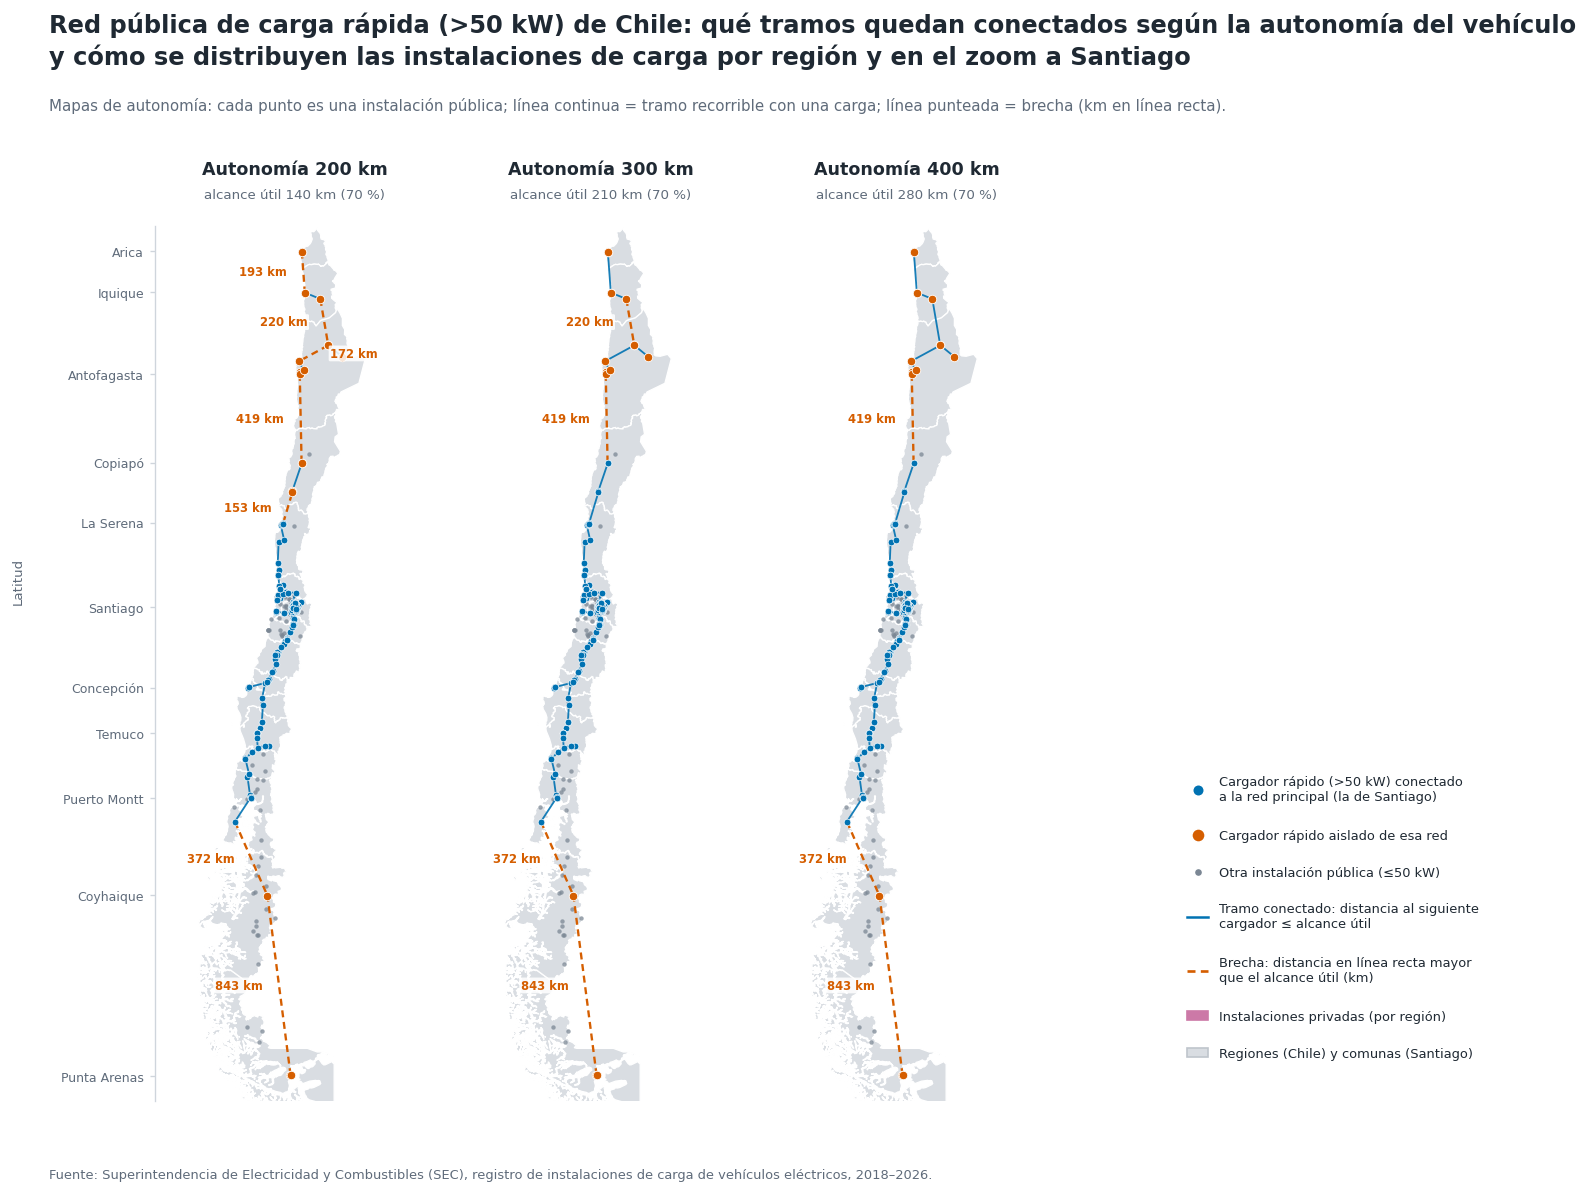

In [41]:
# Requiere haber ejecutado antes: la celda de la red (H3a) y la celda de mapas (mapas_chile_santiago),
# que dejan definidos g_reg, g_com, COL_REG, COL_COM, norm
assert all(v in globals() for v in ["g_reg", "g_com", "COL_REG", "COL_COM", "norm", "escenario"]), \
    "Ejecuta primero la celda H3a (red) y la celda mapas_chile_santiago (geometrías)."

import matplotlib.patheffects as pe
from matplotlib.path import Path
from matplotlib.patches import PathPatch

plt.rcdefaults()
plt.rcParams.update({"font.family": "DejaVu Sans", "axes.grid": False,
                     "axes.spines.top": False, "axes.spines.right": False})

# ---------- textos (editables; pon "" para ocultar) ----------
TITULO = ("Red pública de carga rápida (>50 kW) de Chile: qué tramos quedan conectados según la autonomía del vehículo\n"
          "y cómo se distribuyen las instalaciones de carga por región y en el zoom a Santiago")
SUBTITULO = ("Mapas de autonomía: cada punto es una instalación pública; línea continua = tramo recorrible con una carga; "
             "línea punteada = brecha (km en línea recta).")
FUENTE = ("Fuente: Superintendencia de Electricidad y Combustibles (SEC), registro de instalaciones de carga de vehículos eléctricos, "
          "2018–2026.")

# ---------- colores de los mapas base ----------
C_OTRAS  = "#7b8794"      # otras públicas: gris oscuro para que se vea sobre el mapa gris
C_MAPA   = "#D9DDE2"      # relleno de regiones / comunas
C_BORDE  = "white"        # márgenes blancos entre regiones / comunas
ETIQUETAS_COMUNAS = ["Santiago", "Providencia", "Las Condes", "Maipú", "Puente Alto", "Pudahuel", "La Florida", "Lo Barnechea"]

# ---------- proyecciones simples a km ----------
def a_km(lat, lon, lat0=-36):          # x: este-oeste, y: norte-sur
    return (lon + 70) * 111.2 * np.cos(np.radians(lat0)), lat * 111.2
def proy_chile(lon, lat): return a_km(lat, lon)
def proy_stgo(lon, lat):  return (lon + 70.65) * 111.2 * np.cos(np.radians(-33.45)), (lat + 33.45) * 111.2

# ---------- dibujo de polígonos ----------
def _poligonos(gi):
    t = gi["type"]
    if t == "Polygon":            return [gi["coordinates"]]
    if t == "MultiPolygon":       return list(gi["coordinates"])
    if t == "GeometryCollection": return [p for g in gi["geometries"] for p in _poligonos(g)]
    return []
def _path(gi, proy):
    verts, codes = [], []
    for poly in _poligonos(gi):
        for anillo in poly:
            xy = np.array([c[:2] for c in anillo], dtype=float)
            if len(xy) < 3: continue
            x, y = proy(xy[:, 0], xy[:, 1])
            verts.append(np.column_stack([x, y]))
            codes.append([Path.MOVETO] + [Path.LINETO] * (len(xy) - 2) + [Path.CLOSEPOLY])
    return Path(np.vstack(verts), np.concatenate(codes)) if verts else None
def dibujar(ax, items, proy, fc=C_MAPA, ec=C_BORDE, lw=.8, z=1):
    for nombre, gi in items:
        p = _path(gi, proy)
        if p is not None: ax.add_patch(PathPatch(p, fc=fc, ec=ec, lw=lw, zorder=z))
def centro(gi, proy):
    mejor = None
    for poly in _poligonos(gi):
        xy = np.array([c[:2] for c in poly[0]], dtype=float); x, y = proy(xy[:, 0], xy[:, 1])
        area = (x.max() - x.min()) * (y.max() - y.min())
        if mejor is None or area > mejor[0]: mejor = (area, (x.min() + x.max()) / 2, (y.min() + y.max()) / 2)
    return mejor[1:]

items_reg = [(str(n), g.__geo_interface__) for n, g in zip(g_reg[COL_REG], g_reg.geometry)]
items_com = [(str(n), g.simplify(0.0005).__geo_interface__) for n, g in zip(g_com[COL_COM], g_com.geometry)]

# ---------- lienzo ----------
fig = plt.figure(figsize=(17, 10.2), dpi=120, facecolor="white")
def txt(x, y, s, **k): return fig.text(x, y, s, **k)

txt(0.03, 0.975, TITULO, fontsize=14.5, fontweight="bold", color=C_TXT, va="top", linespacing=1.35)
if SUBTITULO: txt(0.03, 0.905, SUBTITULO, fontsize=9, color=C_SUAVE, va="top")

# ---------- 3 mapas (facetas por autonomía) ----------
H0, H1, mw = 0.085, 0.80, 0.137
xs = [0.082, 0.232, 0.382]
ymin, ymax = -54.2, -17.4
xr = (ymax - ymin) * 111.2 * (mw * 17) / ((H1 - H0) * 10.2)
axes_m = []
for k, (auto, x0) in enumerate(zip(ESCENARIOS, xs)):
    ax = fig.add_axes([x0, H0, mw, H1 - H0]); axes_m.append(ax)
    R = auto * FACTOR_USO
    main, nc = escenario(R)
    ax.set_xlim(-xr/2 - 60, xr/2 - 60); ax.set_ylim(ymin * 111.2, ymax * 111.2)
    dibujar(ax, items_reg, proy_chile, z=1)                                   # regiones en gris con bordes blancos
    ox, oy = a_km(otras.LATITUD.values, otras.LONGITUD.values)
    ax.scatter(ox, oy, s=7, c=C_OTRAS, alpha=.75, lw=0, zorder=2)
    fx, fy = a_km(rapidos.LATITUD.values, rapidos.LONGITUD.values)
    for w, i, j in aristas:
        if w <= R: ax.plot([fx[i], fx[j]], [fy[i], fy[j]], color=C_CONECT, lw=1.1, alpha=.9, zorder=3)
        else:      ax.plot([fx[i], fx[j]], [fy[i], fy[j]], color=C_AISLA, lw=1.4, ls=(0, (3, 2)), zorder=3)
    ax.scatter(fx[main],  fy[main],  s=16, c=C_CONECT, ec="white", lw=.4, zorder=4)
    ax.scatter(fx[~main], fy[~main], s=26, c=C_AISLA,  ec="white", lw=.5, zorder=5)
    for w, i, j in sorted([e for e in aristas if e[0] > R], reverse=True):
        mx, my = (fx[i] + fx[j]) / 2, (fy[i] + fy[j]) / 2
        lado = -1 if my < -33 * 111.2 else (1 if int(abs(my) / 111.2) % 2 == 0 else -1)
        ax.annotate(f"{w:.0f} km", (mx, my), xytext=(10 * lado, 0), textcoords="offset points",
                    ha="left" if lado > 0 else "right", va="center", fontsize=7, color=C_AISLA,
                    fontweight="bold", bbox=dict(boxstyle="round,pad=0.12", fc="white", ec="none", alpha=.85), zorder=6)
    ax.set_xticks([])
    for s in ["top", "right", "bottom"]: ax.spines[s].set_visible(False)
    ax.spines["left"].set_color("#cfd5dc")
    if k == 0:
        ax.set_yticks([c[1] * 111.2 for c in CIUDADES]); ax.set_yticklabels([c[0] for c in CIUDADES], fontsize=7.5, color=C_SUAVE)
        ax.tick_params(axis="y", length=3, color="#cfd5dc")
    else:
        ax.set_yticks([]); ax.spines["left"].set_visible(False)
    ax.set_aspect("equal", adjustable="box")
    cx = x0 + mw / 2
    txt(cx, 0.842, f"Autonomía {auto} km", fontsize=10.5, fontweight="bold", color=C_TXT, ha="center")
    txt(cx, 0.822, f"alcance útil {R:.0f} km ({FACTOR_USO*100:.0f} %)", fontsize=8, color=C_SUAVE, ha="center")
txt(0.012, 0.51, "Latitud", fontsize=8, color=C_SUAVE, rotation=90, va="center")

# ---------- leyenda ----------
items = [(Line2D([0],[0], marker="o", color="w", mfc=C_CONECT, mec="white", ms=7), "Cargador rápido (>50 kW) conectado\na la red principal (la de Santiago)"),
         (Line2D([0],[0], marker="o", color="w", mfc=C_AISLA, mec="white", ms=8), "Cargador rápido aislado de esa red"),
         (Line2D([0],[0], marker="o", color="w", mfc=C_OTRAS, ms=5), "Otra instalación pública (≤50 kW)"),
         (Line2D([0],[0], color=C_CONECT, lw=1.5), "Tramo conectado: distancia al siguiente\ncargador ≤ alcance útil"),
         (Line2D([0],[0], color=C_AISLA, lw=1.6, ls=(0, (3, 2))), "Brecha: distancia en línea recta mayor\nque el alcance útil (km)"),
         (Patch(color=C_PRIV), "Instalaciones privadas (por región)"),
         (Patch(fc=C_MAPA, ec="#bfc5cc"), "Regiones (Chile) y comunas (Santiago)")]
yl = 0.352
for h, t in items:
    fig.legend([h], [t], loc="upper left", bbox_to_anchor=(RX0, yl + 0.004), frameon=False,
               fontsize=7.8, handlelength=1.6, borderpad=0, labelcolor=C_TXT)
    yl -= 0.044 if "\n" in t else 0.03
if FUENTE: txt(0.03, 0.03, FUENTE, fontsize=7.8, color=C_SUAVE, va="top")

fig.savefig(RUTA_PNG, dpi=220, facecolor="white")
print("Guardado:", RUTA_PNG)
plt.show()

Guardado: hito3_visualizacion_global_solo_chile_anotado.png


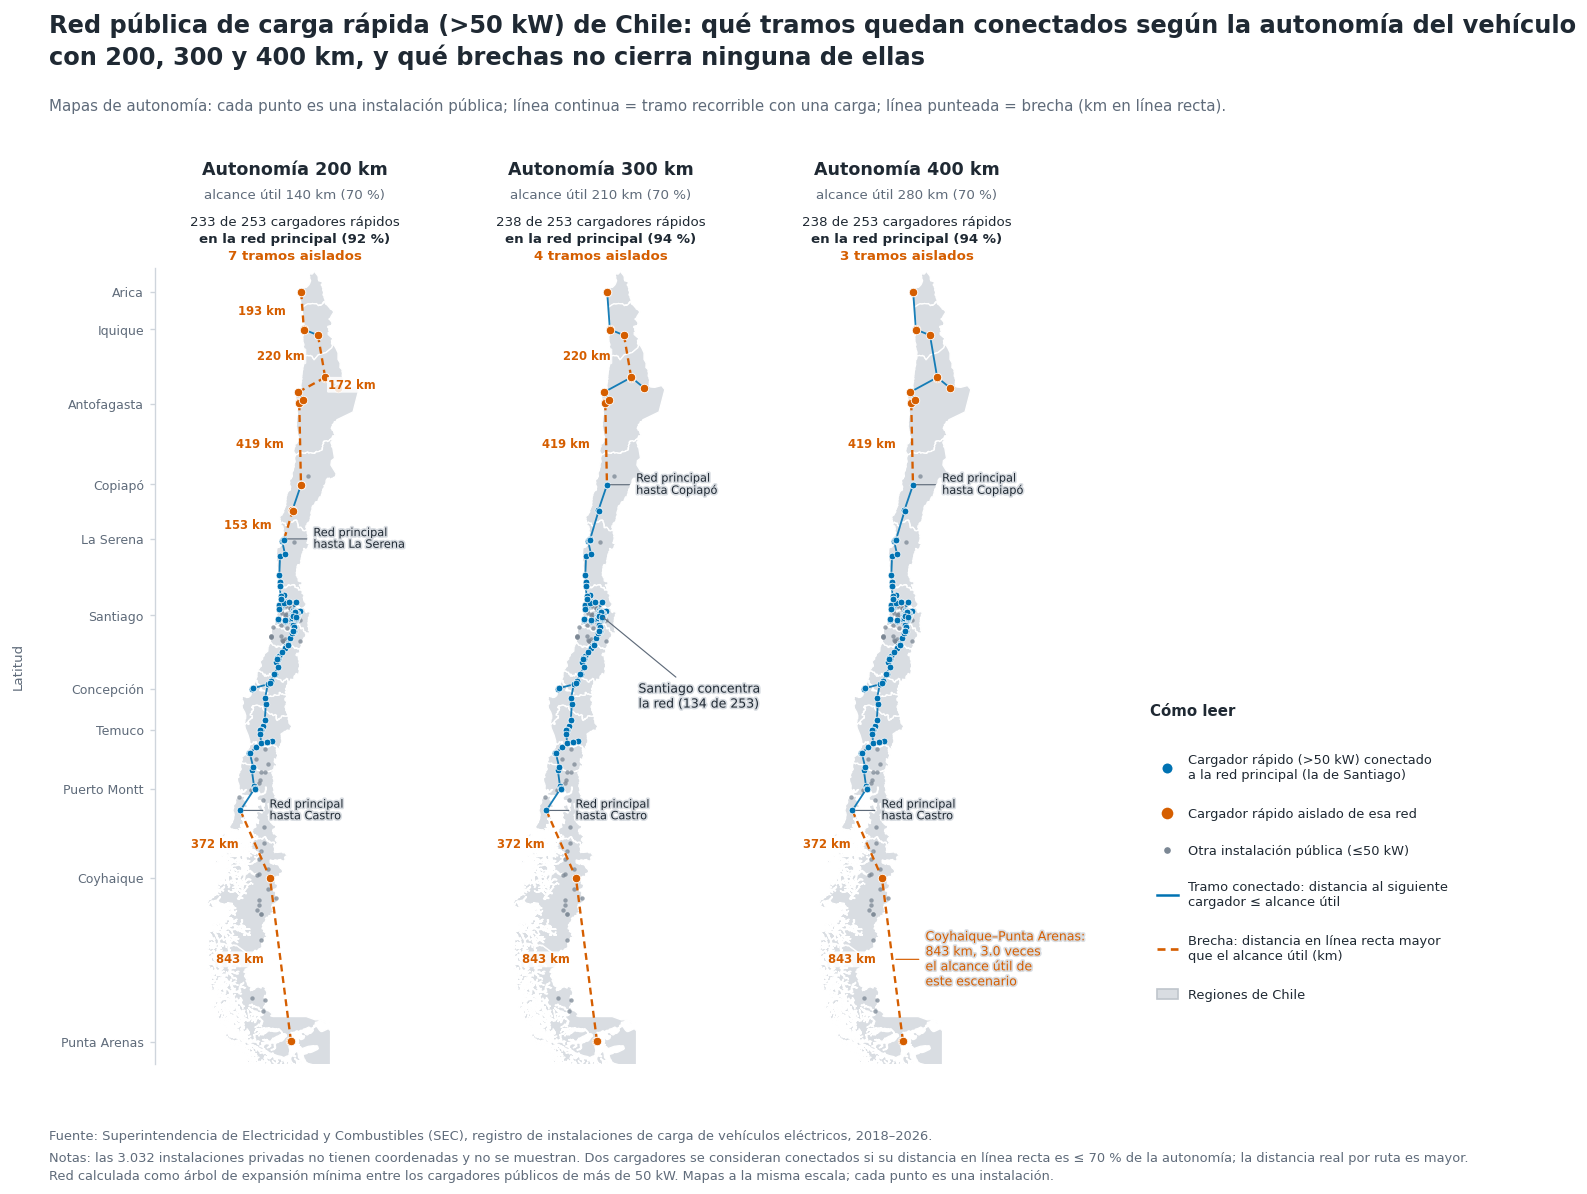

In [45]:
# Requiere haber ejecutado antes: la celda de la red (H3a) y la celda de mapas (mapas_chile_santiago),
# que dejan definidos g_reg, g_com, COL_REG, COL_COM, norm
assert all(v in globals() for v in ["g_reg", "g_com", "COL_REG", "COL_COM", "norm", "escenario"]), \
    "Ejecuta primero la celda H3a (red) y la celda mapas_chile_santiago (geometrías)."

import matplotlib.patheffects as pe
from matplotlib.path import Path
from matplotlib.patches import PathPatch

plt.rcdefaults()
plt.rcParams.update({"font.family": "DejaVu Sans", "axes.grid": False,
                     "axes.spines.top": False, "axes.spines.right": False})

# ---------- textos (editables; pon "" para ocultar) ----------
TITULO = ("Red pública de carga rápida (>50 kW) de Chile: qué tramos quedan conectados según la autonomía del vehículo\n"
          "con 200, 300 y 400 km, y qué brechas no cierra ninguna de ellas")
SUBTITULO = ("Mapas de autonomía: cada punto es una instalación pública; línea continua = tramo recorrible con una carga; "
             "línea punteada = brecha (km en línea recta).")
FUENTE = ("Fuente: Superintendencia de Electricidad y Combustibles (SEC), registro de instalaciones de carga de vehículos eléctricos, "
          "2018–2026.")
NOTAS = ("Notas: las 3.032 instalaciones privadas no tienen coordenadas y no se muestran. Dos cargadores se consideran conectados si su distancia en línea recta "
         "es ≤ 70 % de la autonomía; la distancia real por ruta es mayor.\n"
         "Red calculada como árbol de expansión mínima entre los cargadores públicos de más de 50 kW. Mapas a la misma escala; cada punto es una instalación.")

# ---------- colores de los mapas base ----------
C_OTRAS  = "#7b8794"      # otras públicas: gris oscuro para que se vea sobre el mapa gris
C_MAPA   = "#D9DDE2"      # relleno de regiones / comunas
C_BORDE  = "white"        # márgenes blancos entre regiones / comunas
ETIQUETAS_COMUNAS = ["Santiago", "Providencia", "Las Condes", "Maipú", "Puente Alto", "Pudahuel", "La Florida", "Lo Barnechea"]

# ---------- proyecciones simples a km ----------
def a_km(lat, lon, lat0=-36):          # x: este-oeste, y: norte-sur
    return (lon + 70) * 111.2 * np.cos(np.radians(lat0)), lat * 111.2
def proy_chile(lon, lat): return a_km(lat, lon)
def proy_stgo(lon, lat):  return (lon + 70.65) * 111.2 * np.cos(np.radians(-33.45)), (lat + 33.45) * 111.2

# ---------- dibujo de polígonos ----------
def _poligonos(gi):
    t = gi["type"]
    if t == "Polygon":            return [gi["coordinates"]]
    if t == "MultiPolygon":       return list(gi["coordinates"])
    if t == "GeometryCollection": return [p for g in gi["geometries"] for p in _poligonos(g)]
    return []
def _path(gi, proy):
    verts, codes = [], []
    for poly in _poligonos(gi):
        for anillo in poly:
            xy = np.array([c[:2] for c in anillo], dtype=float)
            if len(xy) < 3: continue
            x, y = proy(xy[:, 0], xy[:, 1])
            verts.append(np.column_stack([x, y]))
            codes.append([Path.MOVETO] + [Path.LINETO] * (len(xy) - 2) + [Path.CLOSEPOLY])
    return Path(np.vstack(verts), np.concatenate(codes)) if verts else None
def dibujar(ax, items, proy, fc=C_MAPA, ec=C_BORDE, lw=.8, z=1):
    for nombre, gi in items:
        p = _path(gi, proy)
        if p is not None: ax.add_patch(PathPatch(p, fc=fc, ec=ec, lw=lw, zorder=z))
def centro(gi, proy):
    mejor = None
    for poly in _poligonos(gi):
        xy = np.array([c[:2] for c in poly[0]], dtype=float); x, y = proy(xy[:, 0], xy[:, 1])
        area = (x.max() - x.min()) * (y.max() - y.min())
        if mejor is None or area > mejor[0]: mejor = (area, (x.min() + x.max()) / 2, (y.min() + y.max()) / 2)
    return mejor[1:]

items_reg = [(str(n), g.__geo_interface__) for n, g in zip(g_reg[COL_REG], g_reg.geometry)]
items_com = [(str(n), g.simplify(0.0005).__geo_interface__) for n, g in zip(g_com[COL_COM], g_com.geometry)]

# ---------- lienzo ----------
fig = plt.figure(figsize=(17, 10.2), dpi=120, facecolor="white")
def txt(x, y, s, **k): return fig.text(x, y, s, **k)

txt(0.03, 0.975, TITULO, fontsize=14.5, fontweight="bold", color=C_TXT, va="top", linespacing=1.35)
if SUBTITULO: txt(0.03, 0.905, SUBTITULO, fontsize=9, color=C_SUAVE, va="top")

# ---------- 3 mapas (facetas por autonomía) ----------
H0, H1, mw = 0.115, 0.765, 0.137
xs = [0.082, 0.232, 0.382]
ymin, ymax = -54.2, -17.4
xr = (ymax - ymin) * 111.2 * (mw * 17) / ((H1 - H0) * 10.2)
axes_m = []
for k, (auto, x0) in enumerate(zip(ESCENARIOS, xs)):
    ax = fig.add_axes([x0, H0, mw, H1 - H0]); axes_m.append(ax)
    R = auto * FACTOR_USO
    main, nc = escenario(R)
    ax.set_xlim(-xr/2 - 60, xr/2 - 60); ax.set_ylim(ymin * 111.2, ymax * 111.2)
    dibujar(ax, items_reg, proy_chile, z=1)                                   # regiones en gris con bordes blancos
    ox, oy = a_km(otras.LATITUD.values, otras.LONGITUD.values)
    ax.scatter(ox, oy, s=7, c=C_OTRAS, alpha=.75, lw=0, zorder=2)
    fx, fy = a_km(rapidos.LATITUD.values, rapidos.LONGITUD.values)
    for w, i, j in aristas:
        if w <= R: ax.plot([fx[i], fx[j]], [fy[i], fy[j]], color=C_CONECT, lw=1.1, alpha=.9, zorder=3)
        else:      ax.plot([fx[i], fx[j]], [fy[i], fy[j]], color=C_AISLA, lw=1.4, ls=(0, (3, 2)), zorder=3)
    ax.scatter(fx[main],  fy[main],  s=16, c=C_CONECT, ec="white", lw=.4, zorder=4)
    ax.scatter(fx[~main], fy[~main], s=26, c=C_AISLA,  ec="white", lw=.5, zorder=5)
    for w, i, j in sorted([e for e in aristas if e[0] > R], reverse=True):
        mx, my = (fx[i] + fx[j]) / 2, (fy[i] + fy[j]) / 2
        lado = -1 if my < -33 * 111.2 else (1 if int(abs(my) / 111.2) % 2 == 0 else -1)
        ax.annotate(f"{w:.0f} km", (mx, my), xytext=(10 * lado, 0), textcoords="offset points",
                    ha="left" if lado > 0 else "right", va="center", fontsize=7, color=C_AISLA,
                    fontweight="bold", bbox=dict(boxstyle="round,pad=0.12", fc="white", ec="none", alpha=.85), zorder=6)
    ax.set_xticks([])
    for s in ["top", "right", "bottom"]: ax.spines[s].set_visible(False)
    ax.spines["left"].set_color("#cfd5dc")
    if k == 0:
        ax.set_yticks([c[1] * 111.2 for c in CIUDADES]); ax.set_yticklabels([c[0] for c in CIUDADES], fontsize=7.5, color=C_SUAVE)
        ax.tick_params(axis="y", length=3, color="#cfd5dc")
    else:
        ax.set_yticks([]); ax.spines["left"].set_visible(False)
    ax.set_aspect("equal", adjustable="box")
    cx = x0 + mw / 2
    txt(cx, 0.842, f"Autonomía {auto} km", fontsize=10.5, fontweight="bold", color=C_TXT, ha="center")
    txt(cx, 0.822, f"alcance útil {R:.0f} km ({FACTOR_USO*100:.0f} %)", fontsize=8, color=C_SUAVE, ha="center")
    nm = int(main.sum())
    txt(cx, 0.803, f"{nm} de {n_rap} cargadores rápidos", fontsize=8, color=C_TXT, ha="center", va="center")
    txt(cx, 0.789, f"en la red principal ({nm/n_rap*100:.0f} %)", fontsize=8, fontweight="bold", color=C_TXT, ha="center", va="center")
    txt(cx, 0.775, f"{nc-1} tramos aislados", fontsize=8, fontweight="bold", color=C_AISLA, ha="center", va="center")
    # dónde termina la red principal (norte y sur)
    idx = np.where(main)[0]
    for i_ext in (idx[np.argmax(fy[idx])], idx[np.argmin(fy[idx])]):
        ax.annotate(f"Red principal\nhasta {rapidos.COMUNA_INSTALACION[i_ext]}", xy=(fx[i_ext], fy[i_ext]), xytext=(fx[i_ext] + 150, fy[i_ext]),
                    fontsize=6.8, color=C_TXT, ha="left", va="center", zorder=7,
                    arrowprops=dict(arrowstyle="-", color=C_SUAVE, lw=.7),
                    path_effects=[pe.withStroke(linewidth=2, foreground=C_MAPA)])
txt(0.012, 0.44, "Latitud", fontsize=8, color=C_SUAVE, rotation=90, va="center")

# anotación: concentración en Santiago (mapa del medio)
n_rm_rap = int((rapidos["REGION_INSTALACION"] == "Metropolitana").sum())
axes_m[1].annotate(f"Santiago concentra\nla red ({n_rm_rap} de {n_rap})", xy=(a_km(-33.45, -70.65)[0], -33.45 * 111.2),
                   xytext=(135, -37.2 * 111.2), fontsize=7.5, color=C_TXT, va="center", zorder=7,
                   arrowprops=dict(arrowstyle="-", color=C_SUAVE, lw=.7),
                   path_effects=[pe.withStroke(linewidth=2, foreground=C_MAPA)])
# anotación: la brecha más larga (último mapa)
R_u = ESCENARIOS[-1] * FACTOR_USO
w_max, i_max, j_max = max(aristas, key=lambda e: e[0])
ym = (fy[i_max] + fy[j_max]) / 2; xm = (fx[i_max] + fx[j_max]) / 2
axes_m[-1].annotate(f"{rapidos.COMUNA_INSTALACION[j_max]}–{rapidos.COMUNA_INSTALACION[i_max]}:\n{w_max:.0f} km, {w_max / R_u:.1f} veces\nel alcance útil de\neste escenario",
                    xy=(xm, ym), xytext=(xm + 170, ym), fontsize=7.5, color=C_AISLA, va="center", zorder=7,
                    arrowprops=dict(arrowstyle="-", color=C_AISLA, lw=.7),
                    path_effects=[pe.withStroke(linewidth=2, foreground=C_MAPA)])

# ---------- leyenda ----------
RX0 = 0.57          # posición horizontal de la leyenda (fracción del ancho)
items = [(Line2D([0],[0], marker="o", color="w", mfc=C_CONECT, mec="white", ms=7), "Cargador rápido (>50 kW) conectado\na la red principal (la de Santiago)"),
         (Line2D([0],[0], marker="o", color="w", mfc=C_AISLA, mec="white", ms=8), "Cargador rápido aislado de esa red"),
         (Line2D([0],[0], marker="o", color="w", mfc=C_OTRAS, ms=5), "Otra instalación pública (≤50 kW)"),
         (Line2D([0],[0], color=C_CONECT, lw=1.5), "Tramo conectado: distancia al siguiente\ncargador ≤ alcance útil"),
         (Line2D([0],[0], color=C_AISLA, lw=1.6, ls=(0, (3, 2))), "Brecha: distancia en línea recta mayor\nque el alcance útil (km)"),
         (Patch(fc=C_MAPA, ec="#bfc5cc"), "Regiones de Chile")]
txt(RX0, 0.40, "Cómo leer", fontsize=9, fontweight="bold", color=C_TXT)
yl = 0.37
for h, t in items:
    fig.legend([h], [t], loc="upper left", bbox_to_anchor=(RX0, yl + 0.004), frameon=False,
               fontsize=7.8, handlelength=1.6, borderpad=0, labelcolor=C_TXT)
    yl -= 0.044 if "\n" in t else 0.03
if FUENTE: txt(0.03, 0.062, FUENTE, fontsize=7.8, color=C_SUAVE, va="top")
if NOTAS:  txt(0.03, 0.044, NOTAS, fontsize=7.8, color=C_SUAVE, va="top", linespacing=1.5)

fig.savefig(RUTA_PNG, dpi=220, facecolor="white")
print("Guardado:", RUTA_PNG)
plt.show()

Guardado: hito3_visualizacion_global_solo_chile_anotado_FINAL.png


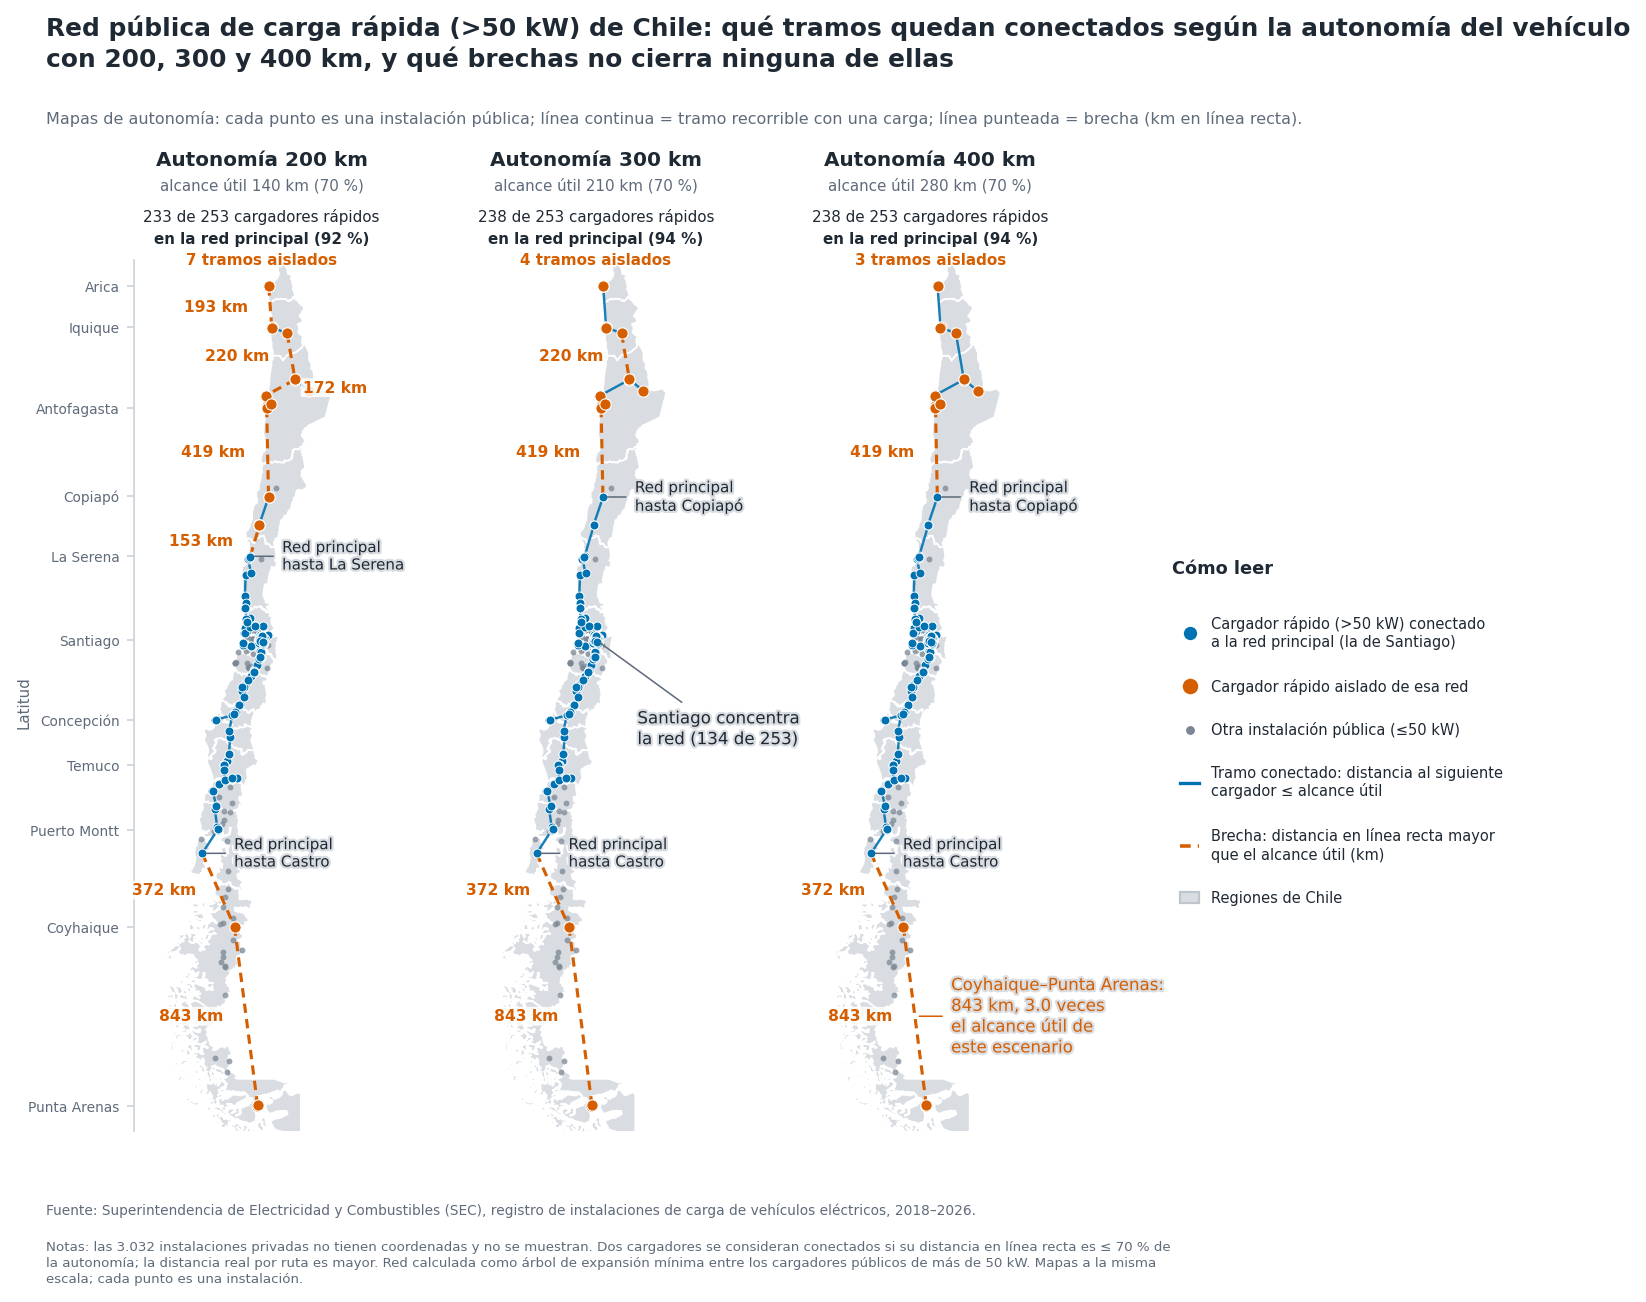

In [47]:
# Requiere haber ejecutado antes: la celda de la red (H3a) y la celda de mapas (mapas_chile_santiago),
# que dejan definidos g_reg, g_com, COL_REG, COL_COM, norm
assert all(v in globals() for v in ["g_reg", "g_com", "COL_REG", "COL_COM", "norm", "escenario"]), \
    "Ejecuta primero la celda H3a (red) y la celda mapas_chile_santiago (geometrías)."

import textwrap
import matplotlib.patheffects as pe
from matplotlib.path import Path
from matplotlib.patches import PathPatch

plt.rcdefaults()
plt.rcParams.update({"font.family": "DejaVu Sans", "axes.grid": False,
                     "axes.spines.top": False, "axes.spines.right": False})

# ---------- textos (editables; pon "" para ocultar) ----------
TITULO = ("Red pública de carga rápida (>50 kW) de Chile: qué tramos quedan conectados según la autonomía del vehículo\n"
          "con 200, 300 y 400 km, y qué brechas no cierra ninguna de ellas")
SUBTITULO = ("Mapas de autonomía: cada punto es una instalación pública; línea continua = tramo recorrible con una carga; "
             "línea punteada = brecha (km en línea recta).")
FUENTE = ("Fuente: Superintendencia de Electricidad y Combustibles (SEC), registro de instalaciones de carga de vehículos eléctricos, "
          "2018–2026.")
NOTAS = ("Notas: las 3.032 instalaciones privadas no tienen coordenadas y no se muestran. Dos cargadores se consideran conectados si su distancia en línea recta "
         "es ≤ 70 % de la autonomía; la distancia real por ruta es mayor.\n"
         "Red calculada como árbol de expansión mínima entre los cargadores públicos de más de 50 kW. Mapas a la misma escala; cada punto es una instalación.")

# ---------- colores de los mapas base ----------
C_OTRAS  = "#7b8794"      # otras públicas: gris oscuro para que se vea sobre el mapa gris
C_MAPA   = "#D9DDE2"      # relleno de regiones / comunas
C_BORDE  = "white"        # márgenes blancos entre regiones / comunas
ETIQUETAS_COMUNAS = ["Santiago", "Providencia", "Las Condes", "Maipú", "Puente Alto", "Pudahuel", "La Florida", "Lo Barnechea"]

# ---------- proyecciones simples a km ----------
def a_km(lat, lon, lat0=-36):          # x: este-oeste, y: norte-sur
    return (lon + 70) * 111.2 * np.cos(np.radians(lat0)), lat * 111.2
def proy_chile(lon, lat): return a_km(lat, lon)
def proy_stgo(lon, lat):  return (lon + 70.65) * 111.2 * np.cos(np.radians(-33.45)), (lat + 33.45) * 111.2

# ---------- dibujo de polígonos ----------
def _poligonos(gi):
    t = gi["type"]
    if t == "Polygon":            return [gi["coordinates"]]
    if t == "MultiPolygon":       return list(gi["coordinates"])
    if t == "GeometryCollection": return [p for g in gi["geometries"] for p in _poligonos(g)]
    return []
def _path(gi, proy):
    verts, codes = [], []
    for poly in _poligonos(gi):
        for anillo in poly:
            xy = np.array([c[:2] for c in anillo], dtype=float)
            if len(xy) < 3: continue
            x, y = proy(xy[:, 0], xy[:, 1])
            verts.append(np.column_stack([x, y]))
            codes.append([Path.MOVETO] + [Path.LINETO] * (len(xy) - 2) + [Path.CLOSEPOLY])
    return Path(np.vstack(verts), np.concatenate(codes)) if verts else None
def dibujar(ax, items, proy, fc=C_MAPA, ec=C_BORDE, lw=.8, z=1):
    for nombre, gi in items:
        p = _path(gi, proy)
        if p is not None: ax.add_patch(PathPatch(p, fc=fc, ec=ec, lw=lw, zorder=z))
def centro(gi, proy):
    mejor = None
    for poly in _poligonos(gi):
        xy = np.array([c[:2] for c in poly[0]], dtype=float); x, y = proy(xy[:, 0], xy[:, 1])
        area = (x.max() - x.min()) * (y.max() - y.min())
        if mejor is None or area > mejor[0]: mejor = (area, (x.min() + x.max()) / 2, (y.min() + y.max()) / 2)
    return mejor[1:]

items_reg = [(str(n), g.__geo_interface__) for n, g in zip(g_reg[COL_REG], g_reg.geometry)]
items_com = [(str(n), g.simplify(0.0005).__geo_interface__) for n, g in zip(g_com[COL_COM], g_com.geometry)]

# ---------- lienzo ----------
fig = plt.figure(figsize=(11, 8.5), dpi=160, facecolor="white")
def txt(x, y, s, **k): return fig.text(x, y, s, **k)

txt(0.035, 0.965, TITULO, fontsize=11.2, fontweight="bold", color=C_TXT, va="top", linespacing=1.25)
if SUBTITULO: txt(0.035, 0.895, SUBTITULO, fontsize=7.2, color=C_SUAVE, va="top")

# ---------- 3 mapas (facetas por autonomía) ----------
H0, H1, mw = 0.145, 0.785, 0.145
xs = [0.085, 0.275, 0.465]
ymin, ymax = -54.2, -17.4
# Mantiene la misma escala geográfica usando las dimensiones reales del lienzo carta.
xr = (ymax - ymin) * 111.2 * (mw * fig.get_figwidth()) / ((H1 - H0) * fig.get_figheight())
axes_m = []
for k, (auto, x0) in enumerate(zip(ESCENARIOS, xs)):
    ax = fig.add_axes([x0, H0, mw, H1 - H0]); axes_m.append(ax)
    R = auto * FACTOR_USO
    main, nc = escenario(R)
    ax.set_xlim(-xr/2 - 60, xr/2 - 60); ax.set_ylim(ymin * 111.2, ymax * 111.2)
    dibujar(ax, items_reg, proy_chile, z=1)                                   # regiones en gris con bordes blancos
    ox, oy = a_km(otras.LATITUD.values, otras.LONGITUD.values)
    ax.scatter(ox, oy, s=7, c=C_OTRAS, alpha=.75, lw=0, zorder=2)
    fx, fy = a_km(rapidos.LATITUD.values, rapidos.LONGITUD.values)
    for w, i, j in aristas:
        if w <= R: ax.plot([fx[i], fx[j]], [fy[i], fy[j]], color=C_CONECT, lw=1.1, alpha=.9, zorder=3)
        else:      ax.plot([fx[i], fx[j]], [fy[i], fy[j]], color=C_AISLA, lw=1.4, ls=(0, (3, 2)), zorder=3)
    ax.scatter(fx[main],  fy[main],  s=16, c=C_CONECT, ec="white", lw=.4, zorder=4)
    ax.scatter(fx[~main], fy[~main], s=26, c=C_AISLA,  ec="white", lw=.5, zorder=5)
    for w, i, j in sorted([e for e in aristas if e[0] > R], reverse=True):
        mx, my = (fx[i] + fx[j]) / 2, (fy[i] + fy[j]) / 2
        lado = -1 if my < -33 * 111.2 else (1 if int(abs(my) / 111.2) % 2 == 0 else -1)
        ax.annotate(f"{w:.0f} km", (mx, my), xytext=(10 * lado, 0), textcoords="offset points",
                    ha="left" if lado > 0 else "right", va="center", fontsize=7, color=C_AISLA,
                    fontweight="bold", bbox=dict(boxstyle="round,pad=0.12", fc="white", ec="none", alpha=.85), zorder=6)
    ax.set_xticks([])
    for s in ["top", "right", "bottom"]: ax.spines[s].set_visible(False)
    ax.spines["left"].set_color("#cfd5dc")
    if k == 0:
        ax.set_yticks([c[1] * 111.2 for c in CIUDADES]); ax.set_yticklabels([c[0] for c in CIUDADES], fontsize=6.2, color=C_SUAVE)
        ax.tick_params(axis="y", length=3, color="#cfd5dc")
    else:
        ax.set_yticks([]); ax.spines["left"].set_visible(False)
    ax.set_aspect("equal", adjustable="box")
    cx = x0 + mw / 2
    txt(cx, 0.855, f"Autonomía {auto} km", fontsize=9.0, fontweight="bold", color=C_TXT, ha="center")
    txt(cx, 0.837, f"alcance útil {R:.0f} km ({FACTOR_USO*100:.0f} %)", fontsize=6.8, color=C_SUAVE, ha="center")
    nm = int(main.sum())
    txt(cx, 0.817, f"{nm} de {n_rap} cargadores rápidos", fontsize=6.8, color=C_TXT, ha="center", va="center")
    txt(cx, 0.801, f"en la red principal ({nm/n_rap*100:.0f} %)", fontsize=6.8, fontweight="bold", color=C_TXT, ha="center", va="center")
    txt(cx, 0.785, f"{nc-1} tramos aislados", fontsize=6.8, fontweight="bold", color=C_AISLA, ha="center", va="center")
    # dónde termina la red principal (norte y sur)
    idx = np.where(main)[0]
    for i_ext in (idx[np.argmax(fy[idx])], idx[np.argmin(fy[idx])]):
        ax.annotate(f"Red principal\nhasta {rapidos.COMUNA_INSTALACION[i_ext]}", xy=(fx[i_ext], fy[i_ext]), xytext=(fx[i_ext] + 150, fy[i_ext]),
                    fontsize=6.8, color=C_TXT, ha="left", va="center", zorder=7,
                    arrowprops=dict(arrowstyle="-", color=C_SUAVE, lw=.7),
                    path_effects=[pe.withStroke(linewidth=2, foreground=C_MAPA)])
txt(0.018, 0.46, "Latitud", fontsize=6.8, color=C_SUAVE, rotation=90, va="center")

# anotación: concentración en Santiago (mapa del medio)
n_rm_rap = int((rapidos["REGION_INSTALACION"] == "Metropolitana").sum())
axes_m[1].annotate(f"Santiago concentra\nla red ({n_rm_rap} de {n_rap})", xy=(a_km(-33.45, -70.65)[0], -33.45 * 111.2),
                   xytext=(135, -37.2 * 111.2), fontsize=7.5, color=C_TXT, va="center", zorder=7,
                   arrowprops=dict(arrowstyle="-", color=C_SUAVE, lw=.7),
                   path_effects=[pe.withStroke(linewidth=2, foreground=C_MAPA)])
# anotación: la brecha más larga (último mapa)
R_u = ESCENARIOS[-1] * FACTOR_USO
w_max, i_max, j_max = max(aristas, key=lambda e: e[0])
ym = (fy[i_max] + fy[j_max]) / 2; xm = (fx[i_max] + fx[j_max]) / 2
axes_m[-1].annotate(f"{rapidos.COMUNA_INSTALACION[j_max]}–{rapidos.COMUNA_INSTALACION[i_max]}:\n{w_max:.0f} km, {w_max / R_u:.1f} veces\nel alcance útil de\neste escenario",
                    xy=(xm, ym), xytext=(xm + 170, ym), fontsize=7.5, color=C_AISLA, va="center", zorder=7,
                    arrowprops=dict(arrowstyle="-", color=C_AISLA, lw=.7),
                    path_effects=[pe.withStroke(linewidth=2, foreground=C_MAPA)])

# ---------- leyenda ----------
RX0 = 0.675         # leyenda en la columna derecha
items = [(Line2D([0],[0], marker="o", color="w", mfc=C_CONECT, mec="white", ms=7), "Cargador rápido (>50 kW) conectado\na la red principal (la de Santiago)"),
         (Line2D([0],[0], marker="o", color="w", mfc=C_AISLA, mec="white", ms=8), "Cargador rápido aislado de esa red"),
         (Line2D([0],[0], marker="o", color="w", mfc=C_OTRAS, ms=5), "Otra instalación pública (≤50 kW)"),
         (Line2D([0],[0], color=C_CONECT, lw=1.5), "Tramo conectado: distancia al siguiente\ncargador ≤ alcance útil"),
         (Line2D([0],[0], color=C_AISLA, lw=1.6, ls=(0, (3, 2))), "Brecha: distancia en línea recta mayor\nque el alcance útil (km)"),
         (Patch(fc=C_MAPA, ec="#bfc5cc"), "Regiones de Chile")]
txt(RX0, 0.555, "Cómo leer", fontsize=8, fontweight="bold", color=C_TXT)
yl = 0.525
for h, t in items:
    fig.legend([h], [t], loc="upper left", bbox_to_anchor=(RX0, yl + 0.004), frameon=False,
               fontsize=6.6, handlelength=1.35, borderpad=0, labelcolor=C_TXT)
    yl -= 0.046 if "\n" in t else 0.032
# Pie de figura ajustado al ancho de carta, con saltos de línea controlados.
fuente_imp = textwrap.fill(FUENTE, width=165) if FUENTE else ""
notas_imp = textwrap.fill(NOTAS, width=165) if NOTAS else ""
if fuente_imp: txt(0.035, 0.092, fuente_imp, fontsize=6.2, color=C_SUAVE, va="top", linespacing=1.25)
if notas_imp:  txt(0.035, 0.064, notas_imp, fontsize=6.0, color=C_SUAVE, va="top", linespacing=1.3)

fig.savefig(RUTA_PNG, dpi=300, facecolor="white")
print("Guardado:", RUTA_PNG)
plt.show()